# Research I · Проверка гипотез H1–H5 на LEVIR-CD

**Готовые модели:** Light / FC-Siam-Diff, Medium / BIT, Heavy / Siamese MiT-B3 Diff — каждая в Full и Resized.
**Задача:** получить измерения для самостоятельной интерпретации, а не автоматически объявить гипотезы доказанными.
Нового обучения, HPO, fine-tuning или замены архитектур нет.

| Гипотеза | Что измеряем | Основной результат |
|---|---|---|
| **H1. Full лучше обнаруживает мелкие изменения** | Pixel recall и recall размеченных областей по размеру | Преимущество Full на маленьких областях минус преимущество на крупных |
| **H2. Heavy точнее определяет границы** | Boundary F1/IoU, ошибки внутри/около границ, геометрия общих обнаружений | Сопоставление улучшения сегментации с изменением числа найденных областей |
| **H3. Ошибки моделей взаимодополняются после согласования thresholds** | PR-кривые, TP/FP Jaccard, CG, OR против отдельно настроенной модели | Есть ли дополнительные правильные обнаружения и каковы дополнительные FP |
| **H4. Максимальный pixel F1 не обязательно означает максимальный object recall** | Ранги шести моделей и парные разности F1/recall | Случаи, когда порядок моделей по двум метрикам расходится |
| **H5. Более высокая точность WHERE не всегда оправдывает дополнительные вычисления** | Качество, latency, ложные сигналы, Pareto и сценарии стоимости | Условия, при которых более дорогая модель оправданна или уступает альтернативе |

**H4 и H5 добавлены к исходным H1–H3.** H4 проверяет различия критериев выбора; H2 — конкретное объяснение геометрического преимущества Heavy. H5 не устанавливает универсальную цену ошибки: денежные оценки доступны только после задания собственных ставок.

## Как запускать

Помести **этот файл** в `satellite-change-intelligence/notebooks/`. Дополнительный `.py` рядом не требуется: аналитический код встроен ниже.
Используй существующее окружение Research I, где уже работают модели. Нужны `torch`, `numpy`, `scipy`, `pandas`, `Pillow`, `matplotlib` и зависимости самого `satchange`. Notebook ничего автоматически не устанавливает.

**Первый Run All:** выполняет validation, проверку исторических метрик, выбор порогов, фиксацию протокола и validation-отчёты. Test выключен.
**Второй этап:** после успешной проверки validation измени `RUN_TEST = False` на `True` в разделе 5 и выполни разделы 5–8. Пороги на test больше не подбираются.

Запускается одна модель за другой на `cuda:0`. Выбери другую свободную GPU в настройках, если она занята. Не запускай два notebook с одинаковым `run_name` одновременно. CPU-анализ границ и компонентов может занимать больше времени, чем сам GPU inference.

Кэш позволяет продолжить прерванный inference. При изменении настроек, исходников, окружения, данных или весов нужен **новый `run_name`**. Старые результаты не удаляются.

## Что выявлено в предоставленном архиве

Это сведения из твоих `metadata.json`, `validation_results.json`, CSV и исходников, а не предположения по стандартным архитектурам.

| Вариант | Архитектурная настройка | Deployment seed | Сохранённый threshold |
|---|---|---:|---:|
| Light Full | `base_channels=32` | 2024 | 0.80 |
| Light Resized | `base_channels=16` | 42 | 0.70 |
| Medium Full | `embedding_dim=64`, `image_size=1024` | 123 | 0.70 |
| Medium Resized | `embedding_dim=32`, `image_size=256` | 123 | 0.70 |
| Heavy Full | MiT-B3, decoder 128 | 42 | 0.80 |
| Heavy Resized | MiT-B3, decoder 128 | 42 | 0.85 |

**H1 сравнивает готовые обученные варианты.** У Light и Medium одновременно меняется ширина модели, а обучение/seed тоже могут различаться. Поэтому результат нельзя приписывать только разрешению.

В архиве для Heavy Resized присутствует только seed 42. По умолчанию здесь анализируются шесть deployment checkpoints, а не выдуманные три повторения каждой модели.

`final_models_metrics.csv` смешивает validation/test поля; он **не используется как источник тестового качества**. `final_models_gpu_cost.csv` содержит другие latency, чем отдельные `benchmark.json`. Поэтому H5 по умолчанию выполняет одинаковый новый **forward-only** benchmark, не выбирая наиболее выгодные цифры из старых файлов.

## Протокол измерений — прочитай до запуска test

**Две разные оценки.** Сначала воспроизводим validation на старой сетке оценки каждого варианта: 256 для Resized, исходная/1024 для Full, при сохранённом threshold. Затем все новые гипотезы оцениваем на **исходной сетке GT**. Для Resized увеличиваем float32 scores после sigmoid билинейно (`align_corners=False`) и только потом применяем threshold. Это новый явно описанный протокол, его числа не обязаны совпадать со старым benchmark.

**Объекты — proxy.** GT-маска не содержит instance IDs. Здесь объект — 8-связная компонента размеченной области изменений, а не гарантированно одно здание. Предсказанные компоненты сопоставляются с GT один-к-одному: максимизируется число допустимых совпадений, затем сумма IoU. Основной критерий `IoU >= 0.5`; `0.1` и `0.25` — анализ чувствительности. Компоненты не удаляются по малой площади. Компоненты на краю изображения сохраняются и помечаются.

Дополнительно записываются доля покрытия каждой GT-области и число полностью пропущенных областей. Это помогает отличать пропуск от неточной формы, но coverage не является самостоятельной метрикой precision объекта.

**H1.** Границы small/medium/large — тертили площади GT на validation, в исходных пикселях. Основной контраст: $(R_F-R_R)_{small}-(R_F-R_R)_{large}$, отдельно для object и pixel recall. Есть дополнительная оценка без граничных компонентов.

**H2.** Boundary F1 при допусках 1/2/4 исходных пикселя; Boundary IoU использует внутренние полосы шириной 2 пикселя с квадратным структурным элементом. Это фиксированный pixel-width вариант, не стандартная настройка 2% диагонали. Ошибки разделены на полосу границы, внутренность и дальний фон. Геометрия общих обнаружений — условная оценка на подмножестве, её нельзя выдавать за качество на всех объектах.

**H3.** Пороги выбираются на validation для recall около 0.80 и 0.90; сохраняется фактически достигнутый recall. TP-, FP- и prediction Jaccard различаются. CG — наша рабочая доля исправленных пропусков лучшей одиночной модели, а не общепринятый универсальный индекс. При отсутствии пропусков знаменатель равен нулю: результат `NaN`, не 0. OR сравнивается с одиночными моделями, перенастроенными на validation к recall этого OR. На test равенство recall не навязывается. Объединение множеств найденных GT и результат связных компонентов OR-маски считаются отдельно: OR может склеить объекты.

**H4.** Основной рейтинг использует `val_f1` — порог максимального pixel F1 на validation. Проверяется расхождение рангов с object recall и чувствительность к IoU. Модели для сравнения выбираются на validation; test-рейтинг остаётся описательным.

**H5.** Основная вычислительная метрика — синхронизированная задержка forward при batch=1, FP32, TF32 выключен. Не включены чтение, preprocessing, перенос на GPU, postprocessing и семантическая стадия. Это **не end-to-end стоимость продукта**. Сумма latency двух моделей — лишь оценка последовательного запуска, не измеренная latency ансамбля.

Денежный сценарий: стоимость forward + проверка **всех** сигналов оператором + заданная пользователем цена пропусков. Неизвестные ставки остаются `None`; их нельзя подменять нулями. Время обучения/HPO здесь заново не измеряется и в этот сценарий не включено.

**Неопределённость.** 95% парные percentile bootstrap интервалы по парам изображений, не по независимым пикселям. При наличии географических групп передай `cluster_csv`. Интервалы условны на фиксированных checkpoints и не измеряют training-seed variability; множественные сравнения не скорректированы. Ранее test уже изучался, поэтому анализ честно обозначен как **exploratory / post-hoc**, а не новое заранее зарегистрированное подтверждение.

## 1. Настройки

Путь уже соответствует твоему серверу. По умолчанию выбраны все шесть моделей, без повторного обучения и без дополнительных seeds.
Ставки и эксплуатационные ограничения можно оставить `None`: тогда H5 всё равно построит Pareto-таблицы и вычислительные сравнения, но не будет придумывать денежную выгоду.

In [1]:
from pathlib import Path

CONFIG = {
    "project_root": "../..",
    "run_name": "H1_H5_v1",
    "dataset_root": None,  # None -> <project_root>/data/LEVIR-CD
    "variants": ("light_full", "light_resized", "medium_full", "medium_resized", "heavy_full", "heavy_resized"),
    "device": "cuda:0",   # Choose ONE currently free GPU.
    "cpu_threads": 4,
    "validation_atol": 0.001,
    "include_other_seeds": False,
    "trust_own_seed_checkpoints": False,
    "recall_targets": (0.80, 0.90),
    "bootstrap_repetitions": 1000,
    "cost_source": "remeasure",
    "benchmark_warmup": 20,
    "benchmark_repetitions": 100,
    "scenario_pairs": 1000,
    "gpu_price_per_hour": None,
    "review_price_per_alert": None,
    "missed_component_price": None,
    "minimum_object_recall": None,
    "maximum_false_alerts_per_pair": None,
    "maximum_forward_ms": None,
    "cluster_csv": None,  # Optional CSV: split,sample_id,cluster_id
}

# For a later seed-sensitivity run, use a NEW run_name and set both:
# CONFIG["include_other_seeds"] = True
# CONFIG["trust_own_seed_checkpoints"] = True  # Only your own trusted checkpoints.
# The deployment seed is never counted twice; missing seed files are not invented.

## 2. Встроенный аналитический код

Ячейка свёрнута для удобства. Она определяет функции, но **не запускает обучение или inference**.
Переиспользуются `LEVIRCDDataset`, model factory и проверенные helper-функции загрузки/runtime из твоего `final_benchmark.py`. Оригинальный `run_final_benchmark()` не вызывается, чтобы не менять финальные артефакты.

Код хранится строкой и компилируется с собственным SHA-256: изменение аналитической реализации инвалидирует кэш. В комплекте ZIP есть тот же код обычным `.py` для просмотра и тестирования.

In [2]:
CORE_SOURCE = r'''"""Read-only LEVIR-CD inference and exploratory H1--H5 analysis.

Project adapter reviewed against the supplied levir_hypotheses_context.zip.
No training, downloads, writes to src/, or changes to final_models/.
"""
from __future__ import annotations

import copy
import gc
import hashlib
import itertools
import json
import math
import os
import platform
import re
import shutil
import subprocess
import sys
import time
import warnings
from collections import OrderedDict
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
from typing import Any, Mapping
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import scipy
import PIL
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from torch.nn import functional as F

IMPLEMENTATION_VERSION = "levir-H1-H5-1.0.0"
VARIANTS = ("light_full", "light_resized", "medium_full", "medium_resized",
            "heavy_full", "heavy_resized")


@dataclass
class Settings:
    project_root: str
    run_name: str = "H1_H5_v1"
    dataset_root: str | None = None
    variants: tuple[str, ...] = VARIANTS
    device: str = "cuda:0"
    include_other_seeds: bool = False
    trust_own_seed_checkpoints: bool = False
    cpu_threads: int = 4
    validation_atol: float = 0.001
    connectivity: int = 2  # 2 = 8-neighbour connectivity in a 2D mask.
    size_quantiles: tuple[float, float] = (1 / 3, 2 / 3)
    iou_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    primary_iou: float = 0.5
    coverage_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    boundary_tolerances_px: tuple[int, ...] = (1, 2, 4)
    primary_boundary_px: int = 2
    recall_targets: tuple[float, ...] = (0.8, 0.9)
    recall_match_tolerance: float = 0.005
    threshold_grid: tuple[float, ...] = tuple(np.linspace(0, 1, 101).tolist())
    bootstrap_repetitions: int = 1000
    bootstrap_seed: int = 20261020
    cost_source: str = "remeasure"  # or "saved_benchmark"; CSV is never used as truth.
    benchmark_warmup: int = 20
    benchmark_repetitions: int = 100
    minimum_free_gib: float = 1.0
    # Monetary values are OPTIONAL user scenarios, not measured market prices.
    gpu_price_per_hour: float | None = None
    review_price_per_alert: float | None = None
    missed_component_price: float | None = None
    scenario_pairs: int = 1000
    minimum_object_recall: float | None = None
    maximum_false_alerts_per_pair: float | None = None
    maximum_forward_ms: float | None = None
    # A CSV mapping split,sample_id,cluster_id can replace image-pair bootstrap units.
    cluster_csv: str | None = None


def _json_value(x: Any) -> Any:
    if isinstance(x, dict):
        return {str(k): _json_value(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_json_value(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, np.ndarray):
        return _json_value(x.tolist())
    if isinstance(x, np.generic):
        return _json_value(x.item())
    if isinstance(x, float) and not math.isfinite(x):
        return None
    return x


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def write_json(path: Path, obj: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    tmp.write_text(json.dumps(_json_value(obj), ensure_ascii=False, indent=2,
                              sort_keys=True, allow_nan=False), encoding="utf-8")
    tmp.replace(path)


def digest(obj: Any) -> str:
    return hashlib.sha256(json.dumps(_json_value(obj), sort_keys=True,
                                     ensure_ascii=False).encode()).hexdigest()


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(8 << 20), b""):
            h.update(block)
    return h.hexdigest()


def safe_div(a: float, b: float) -> float:
    return float(a / b) if b > 0 else float("nan")


def metric_counts(pred: np.ndarray, gt: np.ndarray) -> dict[str, int]:
    if pred.shape != gt.shape or pred.dtype != bool or gt.dtype != bool:
        raise ValueError("Expected aligned 2-D boolean masks.")
    tp = int(np.count_nonzero(pred & gt))
    fp = int(np.count_nonzero(pred & ~gt))
    pos = int(gt.sum())
    return {"tp": tp, "fp": fp, "fn": pos - tp,
            "tn": gt.size - pos - fp}


def binary_metrics(c: Mapping[str, float]) -> dict[str, float]:
    tp, fp, fn = c["tp"], c["fp"], c["fn"]
    return {"pixel_precision": safe_div(tp, tp + fp),
            "pixel_recall": safe_div(tp, tp + fn),
            "pixel_f1": safe_div(2 * tp, 2 * tp + fp + fn),
            "pixel_iou": safe_div(tp, tp + fp + fn)}


def _tag(x: float) -> str:
    return f"{round(100 * x):03d}"


def _threshold_key(t: float) -> str:
    return hashlib.sha256(np.float32(t).tobytes()).hexdigest()[:12]


def boundary(mask: np.ndarray) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      border_value=0)


def _distance_to(mask: np.ndarray) -> np.ndarray:
    if not mask.any():
        return np.full(mask.shape, np.inf, dtype=np.float32)
    return ndi.distance_transform_edt(~mask)


def inner_band(mask: np.ndarray, width: int) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      iterations=width, border_value=0)


def match_components(gt_labels: np.ndarray, pred_labels: np.ndarray,
                     gt_areas: np.ndarray, pred_areas: np.ndarray,
                     iou_thresholds: tuple[float, ...]) -> tuple[dict, dict]:
    """One-to-one max-cardinality matching, then max IoU among such matchings.

    The matrix includes only IDs participating in an eligible IoU edge; tiny
    unrelated predictions still count as unmatched predictions, never disappear.
    """
    ng, npred = len(gt_areas) - 1, len(pred_areas) - 1
    overlap = (gt_labels > 0) & (pred_labels > 0)
    if overlap.any():
        codes = (gt_labels[overlap].astype(np.int64) * (npred + 1)
                 + pred_labels[overlap])
        codes, intersections = np.unique(codes, return_counts=True)
        gi, pi = codes // (npred + 1), codes % (npred + 1)
        ious = intersections / (gt_areas[gi] + pred_areas[pi] - intersections)
    else:
        gi = pi = np.array([], dtype=np.int64)
        ious = np.array([], dtype=float)
    info = {
        "gt_with_multiple_overlapping_pred_components": int(
            np.count_nonzero(np.bincount(gi, minlength=ng + 1)[1:] > 1)),
        "pred_components_overlapping_multiple_gt": int(
            np.count_nonzero(np.bincount(pi, minlength=npred + 1)[1:] > 1)),
    }
    found = {}
    for threshold in iou_thresholds:
        eligible = ious >= threshold
        gids, pids = np.unique(gi[eligible]), np.unique(pi[eligible])
        pairs = {}
        if len(gids) and len(pids):
            if len(gids) * len(pids) > 10_000_000:
                raise MemoryError("Component matching matrix too large; inspect fragmented masks.")
            weight = np.zeros((len(gids), len(pids)), dtype=np.float64)
            rr, cc = np.searchsorted(gids, gi[eligible]), np.searchsorted(pids, pi[eligible])
            # Total tie-breaking contribution < 1: one extra match always wins.
            weight[rr, cc] = 1 + ious[eligible] / (min(len(gids), len(pids)) + 1)
            r, c = linear_sum_assignment(weight, maximize=True)
            keep = weight[r, c] > 0
            for ri, ci in zip(r[keep], c[keep]):
                pairs[int(gids[ri])] = (int(pids[ci]), float(
                    (weight[ri, ci] - 1) * (min(len(gids), len(pids)) + 1)))
        found[threshold] = pairs
    return found, info


def exact_threshold_counts(scores: np.ndarray, gt: np.ndarray,
                           thresholds: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Exact counts on a predeclared grid, no lossy score histogram/rounding."""
    thresholds = thresholds.astype(np.float32)
    index = np.searchsorted(thresholds, scores.ravel(), side="right")
    positive = np.bincount(index[gt.ravel()], minlength=len(thresholds) + 1)
    negative = np.bincount(index[~gt.ravel()], minlength=len(thresholds) + 1)
    return np.cumsum(positive[::-1])[::-1][1:], np.cumsum(negative[::-1])[::-1][1:]


def pair_counts(a: np.ndarray, b: np.ndarray, gt: np.ndarray) -> dict:
    common = a & b
    union = a | b
    return {
        "n_positive": int(gt.sum()), "tp_a": int((a & gt).sum()),
        "tp_b": int((b & gt).sum()), "common_tp": int((common & gt).sum()),
        "a_only_tp": int((a & ~b & gt).sum()),
        "b_only_tp": int((b & ~a & gt).sum()),
        "common_fn": int((~union & gt).sum()),
        "fp_a": int((a & ~gt).sum()), "fp_b": int((b & ~gt).sum()),
        "common_fp": int((common & ~gt).sum()),
        "tp_or": int((union & gt).sum()), "fp_or": int((union & ~gt).sum()),
        "prediction_intersection": int(common.sum()), "prediction_union": int(union.sum()),
    }


def complementarity(c: Mapping[str, float]) -> dict:
    n, best = c["n_positive"], max(c["tp_a"], c["tp_b"])
    return {
        "jaccard_tp": safe_div(c["common_tp"], c["tp_or"]),
        "jaccard_fp": safe_div(c["common_fp"], c["fp_or"]),
        "jaccard_prediction": safe_div(c["prediction_intersection"], c["prediction_union"]),
        "recall_a": safe_div(c["tp_a"], n), "recall_b": safe_div(c["tp_b"], n),
        "precision_a": safe_div(c["tp_a"], c["tp_a"] + c["fp_a"]),
        "precision_b": safe_div(c["tp_b"], c["tp_b"] + c["fp_b"]),
        "recall_or": safe_div(c["tp_or"], n),
        "precision_or": safe_div(c["tp_or"], c["tp_or"] + c["fp_or"]),
        "extra_tp_vs_best": c["tp_or"] - best,
        "delta_recall": safe_div(c["tp_or"] - best, n),
        "complementarity_gain": safe_div(c["tp_or"] - best, n - best),
        "cg_denominator": n - best,
        "recovery_of_a_fn_by_b": safe_div(c["b_only_tp"], n - c["tp_a"]),
        "recovery_of_b_fn_by_a": safe_div(c["a_only_tp"], n - c["tp_b"]),
    }


def pareto_flags(df: pd.DataFrame, maximize: list[str], minimize: list[str]) -> np.ndarray:
    values = np.column_stack([*[df[c].to_numpy(float) for c in maximize],
                              *[-df[c].to_numpy(float) for c in minimize]])
    finite = np.isfinite(values).all(axis=1)
    flags = np.zeros(len(df), dtype=bool)
    for i in np.flatnonzero(finite):
        other = values[finite]
        flags[i] = not np.any(np.all(other >= values[i], axis=1)
                              & np.any(other > values[i], axis=1))
    return flags


class Experiment:
    def __init__(self, settings: Settings):
        self.cfg = settings
        self.root = Path(settings.project_root).expanduser().resolve()
        if not (self.root / "src/satchange/models/factory.py").is_file():
            raise FileNotFoundError(f"Not the project root: {self.root}")
        if not re.fullmatch(r"[A-Za-z0-9_-]+", settings.run_name):
            raise ValueError("run_name must contain only ASCII letters, digits, '-' and '_'.")
        if not settings.variants or len(set(settings.variants)) != len(settings.variants):
            raise ValueError("Select a non-empty set of distinct variants.")
        for name in ("iou_thresholds", "coverage_thresholds", "recall_targets"):
            values = getattr(settings, name)
            if not values or any(not math.isfinite(x) or not 0 < x <= 1 for x in values):
                raise ValueError(f"{name} must contain values in (0,1].")
            if len({_tag(x) for x in values}) != len(values):
                raise ValueError(f"{name}: values need distinct integer-percentage labels.")
        if settings.cpu_threads < 1 or settings.scenario_pairs < 1:
            raise ValueError("cpu_threads and scenario_pairs must be positive.")
        if not 0 < settings.size_quantiles[0] <= settings.size_quantiles[1] < 1:
            raise ValueError("Invalid size quantiles.")
        if any(r < 1 or int(r) != r for r in settings.boundary_tolerances_px):
            raise ValueError("Boundary tolerances must be positive integer native pixels.")
        if settings.connectivity not in (1, 2):
            raise ValueError("connectivity must be 1 (4 neighbours) or 2 (8 neighbours).")
        if settings.primary_iou not in settings.iou_thresholds:
            raise ValueError("primary_iou must be in iou_thresholds.")
        if settings.primary_boundary_px not in settings.boundary_tolerances_px:
            raise ValueError("primary_boundary_px must be in boundary_tolerances_px.")
        if settings.cost_source not in ("remeasure", "saved_benchmark"):
            raise ValueError("cost_source must be remeasure or saved_benchmark.")
        if settings.include_other_seeds and not settings.trust_own_seed_checkpoints:
            raise ValueError("Full seed checkpoints require explicit trust_own_seed_checkpoints=True.")
        if settings.bootstrap_repetitions < 100:
            warnings.warn("Fewer than 100 bootstrap replicates: debugging only, not a stable CI.")
        if settings.benchmark_repetitions < 1 or settings.benchmark_warmup < 0:
            raise ValueError("Invalid benchmark repetition counts.")
        for name in ("gpu_price_per_hour", "review_price_per_alert", "missed_component_price"):
            v = getattr(settings, name)
            if v is not None and (not math.isfinite(v) or v < 0):
                raise ValueError(f"{name} must be nonnegative or None.")
        self.device = torch.device(settings.device)
        if self.device.type == "cuda":
            if not torch.cuda.is_available():
                raise RuntimeError("CUDA unavailable. Choose the project's GPU kernel or set device='cpu'.")
            if self.device.index is None:
                self.device = torch.device("cuda:0")
            if self.device.index >= torch.cuda.device_count():
                raise ValueError("Requested CUDA device is not visible.")
        torch.set_num_threads(settings.cpu_threads)
        src = str(self.root / "src")
        if src not in sys.path:
            sys.path.insert(0, src)
        import satchange
        loaded = Path(satchange.__file__).resolve()
        if not loaded.is_relative_to(self.root / "src"):
            raise RuntimeError(f"Wrong satchange imported from {loaded}. Restart kernel in Research I.")
        from satchange.data.levir_cd import LEVIRCDDataset
        from satchange.models import create_change_model
        from satchange.final_benchmark import _runtime, _load_checkpoint, _instantiate
        self.Dataset = LEVIRCDDataset
        self.create_model = create_change_model
        self.runtime = _runtime  # Reuse the project's FP32/TF32 runtime controls.
        self.project_load_checkpoint = _load_checkpoint
        self.project_instantiate = _instantiate
        self.dataset_root = Path(settings.dataset_root or self.root / "data/LEVIR-CD").expanduser().resolve()
        self.datasets = {s: self.Dataset(self.dataset_root, s, None, transform=None)
                         for s in ("val", "test")}
        self.out = self.root / "artifacts/hypothesis_tests" / settings.run_name
        self.reports = self.out / "reports"
        self.reports.mkdir(parents=True, exist_ok=True)
        self.cache = self.out / "cache"
        self.cache.mkdir(exist_ok=True)
        self.gt_structure = ndi.generate_binary_structure(2, settings.connectivity)
        self.specs = self._specs()
        self.spec_by_id = {s["run_id"]: s for s in self.specs}
        self.primary = [s for s in self.specs if s["primary"]]
        self.source_manifest = {
            str(p.relative_to(self.root)): sha256_file(p)
            for p in sorted((self.root / "src/satchange").rglob("*.py"))}
        self.cluster_map = self._clusters()
        print("Hashing validation/test inputs for cache integrity (no test metrics)...", flush=True)
        self.data_manifest = self._data_manifest()
        self.protocol = {
            "implementation": IMPLEMENTATION_VERSION,
            "implementation_sha256": globals().get("IMPLEMENTATION_SHA256") or (sha256_file(Path(__file__)) if "__file__" in globals() else IMPLEMENTATION_VERSION),
            "settings": asdict(settings), "sources": self.source_manifest,
            "specs": self.specs, "data_manifest": self.data_manifest,
            "cluster_map": self.cluster_map,
            "environment": {"python": platform.python_version(), "torch": str(torch.__version__),
                            "numpy": np.__version__, "pandas": pd.__version__,
                            "scipy": scipy.__version__, "Pillow": PIL.__version__,
                            "cudnn": torch.backends.cudnn.version(),
                            "deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
                            "cuda": torch.version.cuda, "device": str(self.device),
                            "gpu": torch.cuda.get_device_name(self.device)
                            if self.device.type == "cuda" else None},
            "common_grid": "native GT; float32 sigmoid scores; bilinear upsample before >= threshold; align_corners=False",
            "scope": "post-hoc exploratory inference; no new architecture-causal claim",
        }
        self.signature = digest(self.protocol)
        manifest_path = self.out / "run_manifest.json"
        if manifest_path.exists() and read_json(manifest_path)["signature"] != self.signature:
            raise RuntimeError("Run inputs/code/settings changed. Choose a NEW run_name; old caches are preserved.")
        if not manifest_path.exists():
            write_json(manifest_path, {"signature": self.signature, "protocol": self.protocol,
                                      "created_utc": datetime.now(timezone.utc).isoformat()})
        self._audit()
        self.plan = read_json(self.out / "protocol_frozen.json") if (self.out / "protocol_frozen.json").exists() else None
        print(f"Output: {self.out}\nModels/checkpoints: {len(self.specs)}; primary pipelines: {len(self.primary)}")
        self._storage_check()

    def _specs(self) -> list[dict]:
        result = []
        for variant in self.cfg.variants:
            if variant not in VARIANTS:
                raise ValueError(f"Unknown variant: {variant}")
            folder = self.root / "artifacts/final_models" / variant
            meta = read_json(folder / "metadata.json")
            val = read_json(folder / "validation_results.json")
            if not {"model_name", "model_parameters", "image_size", "deployment_seed", "deployment_threshold"} <= meta.keys():
                raise ValueError(f"Incomplete metadata: {folder}")
            dep = int(meta["deployment_seed"])
            rows = {int(r["seed"]): r for r in val["results"]}
            available = sorted(int(p.name.split("_")[1]) for p in folder.glob("seed_*_best.pt"))
            seeds = [dep] + ([s for s in available if s != dep] if self.cfg.include_other_seeds else [])
            for seed in seeds:
                primary = seed == dep
                file = folder / ("deployment_weights.pt" if primary else f"seed_{seed}_best.pt")
                if not file.is_file():
                    raise FileNotFoundError(file)
                if seed not in rows:
                    raise ValueError(f"No validation record for {variant} seed {seed}")
                row = rows[seed]
                threshold = float(meta["deployment_threshold"] if primary else row["validation_threshold"])
                if not 0 < threshold < 1:
                    raise ValueError("Saved thresholds must be in (0,1).")
                if abs(threshold - float(row["validation_threshold"])) > 1e-9:
                    raise ValueError(f"Threshold conflict in {variant}/{seed}")
                image_size = meta["image_size"]  # Respect Medium Full's stored 1024, not an invented None.
                if variant.endswith("resized") and image_size != 256:
                    raise ValueError(f"Unexpected resized geometry for {variant}")
                if variant.endswith("full") and image_size not in (None, 1024):
                    raise ValueError(f"Unexpected full geometry for {variant}")
                result.append({"variant": variant, "run_id": f"{variant}__s{seed}",
                    "family": variant.split("_")[0], "resolution": variant.split("_")[1],
                    "seed": seed, "primary": primary, "image_size": image_size,
                    "model_name": meta["model_name"], "model_parameters": meta["model_parameters"],
                    "saved_threshold": threshold, "weight_file": str(file),
                    "weight_sha256": sha256_file(file),
                    "metadata_sha256": sha256_file(folder / "metadata.json"),
                    "validation_sha256": sha256_file(folder / "validation_results.json"),
                    "benchmark_sha256": sha256_file(folder / "benchmark.json"),
                    "expected_validation_f1": row["validation_f1"],
                    "expected_validation_iou": row["validation_iou"],
                    "expected_validation_pairs": val.get("number_of_pairs"),
                    "available_seed_files": available})
        return result

    def _clusters(self) -> dict:
        if self.cfg.cluster_csv is None:
            return {}
        path = Path(self.cfg.cluster_csv).expanduser()
        df = pd.read_csv(path, dtype=str)
        if not {"split", "sample_id", "cluster_id"} <= set(df):
            raise ValueError("cluster_csv needs split,sample_id,cluster_id columns.")
        if df.duplicated(["split", "sample_id"]).any() or df.isna().any().any():
            raise ValueError("Duplicate or missing cluster identifiers.")
        mapping = {f"{r.split}/{r.sample_id}": r.cluster_id for r in df.itertuples()}
        for split, ds in self.datasets.items():
            for sid in ds.sample_ids:
                if f"{split}/{sid}" not in mapping:
                    raise ValueError(f"Missing cluster for {split}/{sid}")
        return mapping

    def _data_manifest(self) -> dict:
        result = {}
        pair_hashes = {}
        for split, ds in self.datasets.items():
            result[split] = []
            pair_hashes[split] = set()
            for sid in ds.sample_ids:
                row = {"sample_id": sid}
                hashes = []
                for key, files in (("A", ds.before_files), ("B", ds.after_files), ("label", ds.label_files)):
                    p = files[sid]
                    h = sha256_file(p)
                    row[key] = {"file": str(p), "bytes": p.stat().st_size, "sha256": h}
                    hashes.append(h)
                pair_hashes[split].add(tuple(hashes[:2]))
                result[split].append(row)
        if pair_hashes["val"] & pair_hashes["test"]:
            raise ValueError("Identical RGB pairs detected in validation and test. Resolve split leakage first.")
        return result

    def _audit(self) -> None:
        table = pd.DataFrame([{k: s[k] for k in ("run_id", "variant", "seed", "primary", "image_size",
            "model_name", "saved_threshold", "available_seed_files")} | {"parameters": json.dumps(s["model_parameters"])}
                                for s in self.specs])
        table.to_csv(self.reports / "inventory.csv", index=False)
        issues = []
        for family in ("light", "medium", "heavy"):
            group = [s for s in self.primary if s["family"] == family]
            if len(group) == 2 and group[0]["model_parameters"] != group[1]["model_parameters"]:
                issues.append(f"{family}: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.")
        for s in self.primary:
            if len(s["available_seed_files"]) < 2:
                issues.append(f"{s['variant']}: only one seed file; no estimate of training-seed variance.")
        csv = self.root / "artifacts/final_models/final_models_metrics.csv"
        if csv.exists():
            original = pd.read_csv(csv)
            original.to_csv(self.reports / "historical_metrics_csv_NOT_USED.csv", index=False)
            if "f1_key" in original and not original["f1_key"].eq("test_f1").all():
                issues.append("final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.")
        old_cost = self.root / "artifacts/final_models/final_models_gpu_cost.csv"
        costs = []
        if old_cost.exists():
            c = pd.read_csv(old_cost)
            for s in self.primary:
                b = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
                row = c.loc[c["model"] == s["variant"]]
                costs.append({"variant": s["variant"], "benchmark_json_ms": b.get("latency_ms_per_pair"),
                    "cost_csv_ms": float(row.iloc[0]["latency_ms"]) if len(row) else np.nan})
            pd.DataFrame(costs).to_csv(self.reports / "historical_cost_discrepancies.csv", index=False)
            issues.append("Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.")
        issues += ["Connected GT components are change regions, NOT guaranteed building-instance labels.",
                   "Earlier test scores were already inspected: these analyses are exploratory/post-hoc.",
                   "A deployment checkpoint is not an independent replicate of its source seed.",
                   "No automatic hypothesis-proved labels are produced."]
        write_json(self.reports / "audit_notes.json", issues)
        print("\n".join("NOTE: " + x for x in issues), flush=True)

    def _storage_check(self) -> None:
        # Conservative native-cache estimate assuming 1024x1024 native images.
        n = sum(len(ds) for ds in self.datasets.values())
        bytes_needed = sum(n * 4 * ((s["image_size"] or 1024) ** 2) for s in self.specs)
        free = shutil.disk_usage(self.out).free
        print(f"Score cache upper estimate: {bytes_needed / 2**30:.2f} GiB; free disk: {free / 2**30:.1f} GiB.")
        if free < bytes_needed + self.cfg.minimum_free_gib * 2**30:
            warnings.warn("Free disk may be insufficient for all caches. Existing cache files are not deducted from this conservative estimate.")

    def _load_model(self, s: dict) -> torch.nn.Module:
        path = Path(s["weight_file"])
        if sha256_file(path) != s["weight_sha256"]:
            raise RuntimeError(f"Weights changed during run: {path}")
        if s["primary"]:
            state = torch.load(path, map_location="cpu", weights_only=True)
            if not isinstance(state, Mapping) or not state or not all(
                isinstance(v, torch.Tensor) for v in state.values()):
                raise TypeError("deployment_weights.pt must be a plain tensor state_dict.")
        else:
            # Only explicitly trusted, locally produced full checkpoints.
            state, cp = self.project_load_checkpoint(path)
            config = cp.get("parameters", cp.get("config", {})) or {}
            actual_seed = cp.get("seed", config.get("seed"))
            if actual_seed is not None and int(actual_seed) != s["seed"]:
                raise ValueError("Checkpoint seed mismatch.")
            actual_model = cp.get("model_parameters", config.get("model_parameters"))
            if actual_model is not None:
                # Compare recorded values, not invented constructor defaults.
                for key, val in actual_model.items():
                    if key in s["model_parameters"] and _json_value(val) != _json_value(s["model_parameters"][key]):
                        raise ValueError(f"Architecture conflict: {s['run_id']} {key}")
        # Reviewed project helper: no external pretraining download; strict=True.
        return self.project_instantiate(s["model_name"], s["model_parameters"], state)

    def _release(self) -> None:
        gc.collect()
        if self.device.type == "cuda":
            with torch.cuda.device(self.device):
                torch.cuda.empty_cache()

    def _sync(self) -> None:
        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)

    def _native_path(self, s: dict, split: str, index: int) -> Path:
        return self.cache / s["run_id"] / split / f"{index:05d}.npy"

    def _native_score(self, s: dict, split: str, index: int) -> np.ndarray:
        p = self._native_path(s, split, index)
        if not p.is_file():
            raise FileNotFoundError(f"Run inference for {s['run_id']} {split}: {p}")
        a = np.load(p, allow_pickle=False)
        if a.dtype != np.float32 or a.ndim != 2 or not np.isfinite(a).all():
            raise ValueError(f"Invalid cached score file: {p}")
        return a

    def score(self, s: dict, split: str, index: int) -> np.ndarray:
        a = self._native_score(s, split, index)
        shape = self.gt(split, index)["mask"].shape
        if a.shape != shape:
            with torch.inference_mode():
                a = F.interpolate(torch.from_numpy(a)[None, None], size=shape,
                                  mode="bilinear", align_corners=False)[0, 0].numpy()
        return a

    @lru_cache(maxsize=2)
    def gt(self, split: str, index: int) -> dict:
        ds = self.datasets[split]
        sid = ds.sample_ids[index]
        with Image.open(ds.label_files[sid]) as im:
            mask = np.array(im.convert("L"), dtype=np.uint8) > 0
        labels, ng = ndi.label(mask, structure=self.gt_structure)
        areas = np.bincount(labels.ravel(), minlength=ng + 1)
        objects = ndi.find_objects(labels)
        border_ids = set(np.unique(np.concatenate((labels[0], labels[-1], labels[:, 0], labels[:, -1]))))
        b = boundary(mask)
        return {"sample_id": sid, "mask": mask, "labels": labels, "areas": areas,
                "n_gt": ng, "slices": objects, "border_ids": border_ids,
                "boundary": b, "distance": _distance_to(b),
                "inner_band": inner_band(mask, self.cfg.primary_boundary_px)}

    def run_variant(self, variant: str, split: str = "val") -> None:
        if split not in ("val", "test"):
            raise ValueError(split)
        if split == "test" and self.plan is None:
            raise RuntimeError("Freeze the validation protocol before test inference.")
        matching = [s for s in self.specs if s["variant"] == variant]
        if not matching:
            raise ValueError(f"Variant not enabled: {variant}")
        for s in matching:
            self._run_checkpoint(s, split)

    def _run_checkpoint(self, s: dict, split: str) -> None:
        ds = self.Dataset(self.dataset_root, split, s["image_size"], transform=None)
        if ds.sample_ids != self.datasets[split].sample_ids:
            raise ValueError("Sample IDs/order differ between model and native evaluation.")
        folder = self.cache / s["run_id"] / split
        folder.mkdir(parents=True, exist_ok=True)
        completed = folder / "complete.json"
        if completed.exists():
            info = read_json(completed)
            if info["signature"] != self.signature:
                raise RuntimeError("Stale score cache.")
            if all(self._native_path(s, split, i).is_file() for i in range(len(ds))):
                print(f"CACHE {s['run_id']} {split}: {len(ds)} pairs")
                return
        model = None
        count = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}
        parameters = None
        t0 = time.perf_counter()
        try:
            with self.runtime(self.device), torch.inference_mode():
                for i in range(len(ds)):
                    p = self._native_path(s, split, i)
                    sample = ds[i]
                    if p.exists():
                        probabilities = self._native_score(s, split, i)
                    else:
                        if shutil.disk_usage(self.out).free < self.cfg.minimum_free_gib * 2**30:
                            raise OSError("Disk reserve reached. Completed scores preserved; free space and resume.")
                        if model is None:
                            model = self._load_model(s).to(self.device)
                            parameters = sum(p.numel() for p in model.parameters())
                        a = sample["before"][None].to(self.device, dtype=torch.float32)
                        b = sample["after"][None].to(self.device, dtype=torch.float32)
                        logits = model(a, b)
                        if not isinstance(logits, torch.Tensor) or tuple(logits.shape) != (1, 1, *a.shape[-2:]):
                            raise ValueError(f"Unexpected output shape for {s['run_id']}")
                        probabilities = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
                        if not np.isfinite(probabilities).all():
                            raise ValueError("Non-finite predictions.")
                        tmp = p.with_suffix(".tmp")
                        with tmp.open("wb") as f:
                            np.save(f, probabilities, allow_pickle=False)
                        tmp.replace(p)
                        del a, b, logits
                    gt = sample["mask"][0].numpy() >= 0.5
                    if probabilities.shape != gt.shape:
                        raise ValueError("Native output and processed target do not align.")
                    for k, v in metric_counts(probabilities >= np.float32(s["saved_threshold"]), gt).items():
                        count[k] += v
                    if i == 0 or (i + 1) % 16 == 0 or i + 1 == len(ds):
                        print(f"{s['run_id']:25s} {split}: {i+1}/{len(ds)}", flush=True)
            result = {"signature": self.signature, "run_id": s["run_id"], "split": split,
                      "n_pairs": len(ds), "saved_threshold": s["saved_threshold"],
                      "native_counts": count, "native_metrics": binary_metrics(count),
                      "parameters": parameters, "elapsed_with_io_and_cache_seconds": time.perf_counter() - t0}
            write_json(completed, result)
        finally:
            del model
            self._release()

    def _reproduction(self) -> pd.DataFrame:
        rows = []
        for s in self.specs:
            p = self.cache / s["run_id"] / "val/complete.json"
            if not p.exists():
                raise RuntimeError(f"Validation inference incomplete: {s['run_id']}")
            r = read_json(p)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale validation cache.")
            n_ok = s["expected_validation_pairs"] in (None, r["n_pairs"])
            df1 = r["native_metrics"]["pixel_f1"] - s["expected_validation_f1"]
            diou = r["native_metrics"]["pixel_iou"] - s["expected_validation_iou"]
            rows.append({"run_id": s["run_id"], "pairs": r["n_pairs"],
                "native_f1": r["native_metrics"]["pixel_f1"], "saved_f1": s["expected_validation_f1"],
                "native_iou": r["native_metrics"]["pixel_iou"], "saved_iou": s["expected_validation_iou"],
                "delta_f1": df1, "delta_iou": diou,
                "passed": n_ok and abs(df1) <= self.cfg.validation_atol and abs(diou) <= self.cfg.validation_atol})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / "validation_reproduction.csv", index=False)
        if not df["passed"].all():
            raise RuntimeError("Validation reproduction failed. Inspect validation_reproduction.csv. Do not tune on test or bypass this check blindly.")
        return df

    def _curve(self, s: dict) -> pd.DataFrame:
        grid = np.unique(np.array([*self.cfg.threshold_grid, s["saved_threshold"]], dtype=np.float32))
        if np.any(np.diff(grid) <= 0) or grid[0] < 0 or grid[-1] > 1:
            raise ValueError("Thresholds must be unique and in [0,1].")
        tp, fp = np.zeros(len(grid), np.int64), np.zeros(len(grid), np.int64)
        pos = neg = 0
        for i in range(len(self.datasets["val"])):
            g = self.gt("val", i)["mask"]
            p, n = exact_threshold_counts(self.score(s, "val", i), g, grid)
            tp += p; fp += n
            pos += int(g.sum()); neg += int((~g).sum())
        records = []
        for t, p, f in zip(grid, tp, fp):
            c = {"tp": int(p), "fp": int(f), "fn": pos-int(p), "tn": neg-int(f)}
            records.append({"run_id": s["run_id"], "threshold": float(t), **c, **binary_metrics(c)})
        return pd.DataFrame(records)

    @staticmethod
    def _at_recall(curve: pd.DataFrame, target: float) -> dict:
        feasible = curve.loc[curve["pixel_recall"] >= target - 1e-12].copy()
        if feasible.empty:
            return {"attainable": False, "target_recall": target, "threshold": None}
        # Minimal recall overshoot, then best precision, then highest threshold.
        row = feasible.sort_values(["pixel_recall", "pixel_precision", "threshold"],
                                   ascending=[True, False, False], na_position="last").iloc[0]
        return {"attainable": True, "target_recall": target, "threshold": float(row["threshold"]),
                "validation_recall": float(row["pixel_recall"]),
                "validation_precision": float(row["pixel_precision"])}

    def _make_operations(self, curves: dict[str, pd.DataFrame]) -> dict:
        operations = {}
        for s in self.specs:
            curve = curves[s["run_id"]]
            best = curve.sort_values(["pixel_f1", "pixel_precision", "threshold"],
                                     ascending=[False, False, False], na_position="last").iloc[0]
            ops = {"saved": {"threshold": s["saved_threshold"], "attainable": True},
                   "val_f1": {"threshold": float(best["threshold"]), "attainable": True,
                              "validation_f1": float(best["pixel_f1"])}}
            for r in self.cfg.recall_targets:
                ops[f"recall_{_tag(r)}"] = self._at_recall(curve, r)
            operations[s["run_id"]] = ops
        return operations

    def _size_cutoffs(self) -> list[float]:
        areas = np.concatenate([self.gt("val", i)["areas"][1:]
                                for i in range(len(self.datasets["val"]))])
        if not len(areas):
            raise ValueError("No validation GT components.")
        cuts = np.quantile(areas, self.cfg.size_quantiles).tolist()
        if cuts[0] == cuts[1]:
            warnings.warn("Tied size cutoffs: some bins can be empty; these metrics remain undefined.")
        return cuts

    def _size(self, area: int, cuts: list[float]) -> str:
        return "small" if area <= cuts[0] else "medium" if area <= cuts[1] else "large"

    def _evaluate_mask(self, pred: np.ndarray, gt: dict, cuts: list[float],
                       geometry: bool = True) -> tuple[dict, list[dict]]:
        g, gl = gt["mask"], gt["labels"]
        pl, npred = ndi.label(pred, structure=self.gt_structure)
        pa = np.bincount(pl.ravel(), minlength=npred + 1)
        matched, overlap_info = match_components(gl, pl, gt["areas"], pa, self.cfg.iou_thresholds)
        inside = np.bincount(gl[pred].ravel(), minlength=gt["n_gt"] + 1)
        band_pixels = np.bincount(gl[gt["inner_band"]].ravel(), minlength=gt["n_gt"] + 1)
        row = {"sample_id": gt["sample_id"], **metric_counts(pred, g),
               "n_gt": gt["n_gt"], "n_pred": npred, **overlap_info}
        for t, pairs in matched.items():
            tag = _tag(t)
            row.update({f"obj_tp_{tag}": len(pairs), f"obj_fp_{tag}": npred-len(pairs),
                        f"obj_fn_{tag}": gt["n_gt"]-len(pairs)})
        for name in ("small", "medium", "large"):
            row.update({f"{name}_gt": 0, f"{name}_tp_pixels": 0,
                        f"{name}_positive_pixels": 0, f"{name}_obj_tp": 0,
                        f"{name}_nonborder_gt": 0, f"{name}_nonborder_obj_tp": 0})
        row["completely_missed_gt"] = int(np.count_nonzero(inside[1:] == 0))
        for t in self.cfg.coverage_thresholds:
            coverage = inside[1:] / gt["areas"][1:]
            row[f"coverage_hits_{_tag(t)}"] = int(np.count_nonzero(coverage >= t))
        if geometry:
            pb = boundary(pred)
            pdistance = _distance_to(pb)
            row.update(boundary_pred_count=int(pb.sum()), boundary_gt_count=int(gt["boundary"].sum()))
            for r in self.cfg.boundary_tolerances_px:
                row[f"boundary_matched_pred_{r}"] = int(np.count_nonzero(pb & (gt["distance"] <= r)))
                row[f"boundary_matched_gt_{r}"] = int(np.count_nonzero(gt["boundary"] & (pdistance <= r)))
            band = inner_band(pred, self.cfg.primary_boundary_px)
            row["boundary_iou_intersection"] = int((band & gt["inner_band"]).sum())
            row["boundary_iou_union"] = int((band | gt["inner_band"]).sum())
            near = gt["distance"] <= self.cfg.primary_boundary_px
            row.update({"boundary_error_count": int(((pred != g) & near).sum()),
                        "boundary_band_pixels": int(near.sum()),
                        "interior_fn": int((~pred & g & ~near).sum()),
                        "interior_pixels": int((g & ~near).sum()),
                        "far_background_fp": int((pred & ~g & ~near).sum()),
                        "far_background_pixels": int((~g & ~near).sum())})
            pred_slices = ndi.find_objects(pl)
        components = []
        primary_pairs = matched[self.cfg.primary_iou]
        for gid in range(1, gt["n_gt"] + 1):
            area = int(gt["areas"][gid])
            size = self._size(area, cuts)
            hit = gid in primary_pairs
            border = gid in gt["border_ids"]
            row[f"{size}_gt"] += 1
            row[f"{size}_obj_tp"] += int(hit)
            row[f"{size}_positive_pixels"] += area
            row[f"{size}_tp_pixels"] += int(inside[gid])
            if not border:
                row[f"{size}_nonborder_gt"] += 1
                row[f"{size}_nonborder_obj_tp"] += int(hit)
            c = {"sample_id": gt["sample_id"], "gt_id": gid,
                 "component_key": f"{gt['sample_id']}::{gid}", "area_px": area,
                 "size_bin": size, "border_truncated": border,
                 "covered_pixels": int(inside[gid]), "coverage": float(inside[gid] / area),
                 "completely_missed": inside[gid] == 0,
                 "has_interior_at_primary_width": bool(area > band_pixels[gid]),
                 "matched_boundary_iou": np.nan, "matched_mask_iou": np.nan}
            for t, pairs in matched.items():
                c[f"detected_iou_{_tag(t)}"] = gid in pairs
                c[f"matched_iou_{_tag(t)}"] = pairs[gid][1] if gid in pairs else np.nan
            if hit:
                pid, iou = primary_pairs[gid]
                c["matched_mask_iou"] = iou
                if geometry:
                    gs, ps = gt["slices"][gid-1], pred_slices[pid-1]
                    region = tuple(slice(min(a.start, b.start), max(a.stop, b.stop))
                                   for a, b in zip(gs, ps))
                    gb = inner_band(gl[region] == gid, self.cfg.primary_boundary_px)
                    pb = inner_band(pl[region] == pid, self.cfg.primary_boundary_px)
                    c["matched_boundary_iou"] = safe_div(int((gb & pb).sum()), int((gb | pb).sum()))
            components.append(c)
        return row, components

    def _counts_to_metrics(self, sums: Mapping[str, float], n_pairs: int) -> dict:
        m = binary_metrics(sums)
        m.update({"gt_components": sums["n_gt"], "predicted_components": sums["n_pred"],
                  "pairs": n_pairs, "alerts_per_pair": safe_div(sums["n_pred"], n_pairs),
                  "completely_missed_fraction": safe_div(sums["completely_missed_gt"], sums["n_gt"])})
        for t in self.cfg.iou_thresholds:
            tag = _tag(t)
            tp, fp, fn = (sums[f"obj_{k}_{tag}"] for k in ("tp", "fp", "fn"))
            m.update({f"object_precision_{tag}": safe_div(tp, tp+fp),
                      f"object_recall_{tag}": safe_div(tp, tp+fn),
                      f"object_f1_{tag}": safe_div(2*tp, 2*tp+fp+fn),
                      f"false_alerts_per_pair_{tag}": safe_div(fp, n_pairs),
                      f"detected_components_{tag}": tp, f"missed_components_{tag}": fn})
        for t in self.cfg.coverage_thresholds:
            m[f"gt_coverage_recall_{_tag(t)}"] = safe_div(sums[f"coverage_hits_{_tag(t)}"], sums["n_gt"])
        for name in ("small", "medium", "large"):
            m[f"{name}_object_recall"] = safe_div(sums[f"{name}_obj_tp"], sums[f"{name}_gt"])
            m[f"{name}_pixel_recall"] = safe_div(sums[f"{name}_tp_pixels"], sums[f"{name}_positive_pixels"])
            m[f"{name}_nonborder_object_recall"] = safe_div(sums[f"{name}_nonborder_obj_tp"], sums[f"{name}_nonborder_gt"])
        if "boundary_pred_count" in sums:
            for r in self.cfg.boundary_tolerances_px:
                p = safe_div(sums[f"boundary_matched_pred_{r}"], sums["boundary_pred_count"])
                recall = safe_div(sums[f"boundary_matched_gt_{r}"], sums["boundary_gt_count"])
                if sums["boundary_pred_count"] == 0 and sums["boundary_gt_count"] > 0:
                    bf = 0.0
                elif sums["boundary_gt_count"] == 0 and sums["boundary_pred_count"] > 0:
                    bf = 0.0
                elif not np.isfinite(p+recall):
                    bf = np.nan
                else:
                    bf = 0.0 if p+recall == 0 else 2*p*recall/(p+recall)
                m[f"boundary_precision_{r}px"] = p
                m[f"boundary_recall_{r}px"] = recall
                m[f"boundary_f1_{r}px"] = bf
            m["boundary_iou"] = safe_div(sums["boundary_iou_intersection"], sums["boundary_iou_union"])
            m["boundary_error_rate"] = safe_div(sums["boundary_error_count"], sums["boundary_band_pixels"])
            m["interior_fn_rate"] = safe_div(sums["interior_fn"], sums["interior_pixels"])
            m["far_background_fp_rate"] = safe_div(sums["far_background_fp"], sums["far_background_pixels"])
        return m

    def _evaluate_operation(self, s: dict, split: str, threshold: float, cuts: list) -> tuple[pd.DataFrame, pd.DataFrame]:
        folder = self.cache / "analysis" / split / s["run_id"] / _threshold_key(threshold)
        marker = folder / "complete.json"
        if marker.exists():
            info = read_json(marker)
            if info["signature"] != self.signature or info["cutoffs"] != cuts:
                raise RuntimeError("Stale metric cache.")
            images = pd.read_csv(folder / "images.csv", dtype={"sample_id": str})
            objects = pd.read_csv(folder / "components.csv", dtype={"sample_id": str})
            return images, objects
        folder.mkdir(parents=True, exist_ok=True)
        image_rows, object_rows = [], []
        for i in range(len(self.datasets[split])):
            scores = self.score(s, split, i)
            row, components = self._evaluate_mask(scores >= np.float32(threshold), self.gt(split, i), cuts)
            image_rows.append(row); object_rows.extend(components)
        images = pd.DataFrame(image_rows)
        objects = pd.DataFrame(object_rows)
        if objects.empty:
            objects = pd.DataFrame(columns=["sample_id", "gt_id", "component_key", "area_px", "size_bin"])
        images.to_csv(folder / "images.csv", index=False)
        objects.to_csv(folder / "components.csv", index=False)
        write_json(marker, {"signature": self.signature, "cutoffs": cuts, "threshold": threshold})
        return images, objects

    def evaluate_split(self, split: str, plan: dict) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        summaries, all_images, all_objects = [], [], []
        for s in self.specs:
            for policy, op in plan["operations"][s["run_id"]].items():
                if not op["attainable"]:
                    continue
                print(f"METRICS {split} {s['run_id']} {policy}", flush=True)
                images, objects = self._evaluate_operation(s, split, op["threshold"], plan["size_cutoffs_px"])
                identity = {"run_id": s["run_id"], "variant": s["variant"], "seed": s["seed"],
                            "primary": s["primary"], "policy": policy, "split": split,
                            "threshold": op["threshold"]}
                sums = images.select_dtypes(include=[np.number]).sum().to_dict()
                summaries.append({**identity, **self._counts_to_metrics(sums, len(images)),
                                  "target_pixel_recall": op.get("target_recall", np.nan),
                                  "validation_recall": op.get("validation_recall", np.nan)})
                all_images.append(images.assign(**identity))
                all_objects.append(objects.assign(**identity))
        summary, per_image, per_object = pd.DataFrame(summaries), pd.concat(all_images, ignore_index=True), pd.concat(all_objects, ignore_index=True)
        summary.to_csv(self.reports / f"{split}_summary.csv", index=False)
        per_image.to_csv(self.reports / f"{split}_per_image.csv", index=False)
        per_object.to_csv(self.reports / f"{split}_per_component.csv", index=False)
        return summary, per_image, per_object

    def benchmark(self, s: dict) -> dict:
        file = self.reports / "cost" / f"{s['run_id']}.json"
        if file.exists():
            r = read_json(file)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale cost benchmark.")
            return r
        if self.cfg.cost_source == "saved_benchmark":
            old = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
            r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                 "latency_ms": old["latency_ms_per_pair"], "parameters": old["parameters"],
                 "peak_allocated_mib": old.get("peak_inference_vram_mb"),
                 "cost_source": "saved_benchmark", "comparable_protocol_verified": False,
                 "protocol": old.get("protocol", {}), "gpu": old.get("gpu_name")}
        else:
            self._release()
            baseline = torch.cuda.memory_allocated(self.device) if self.device.type == "cuda" else 0
            if self.device.type == "cuda":
                torch.cuda.reset_peak_memory_stats(self.device)
            model = a = b = y = None
            try:
                model = self._load_model(s).to(self.device)
                sample = self.Dataset(self.dataset_root, "val", s["image_size"], transform=None)[0]
                a, b = (sample[k][None].to(self.device, dtype=torch.float32) for k in ("before", "after"))
                times = []
                with self.runtime(self.device), torch.inference_mode():
                    for _ in range(self.cfg.benchmark_warmup):
                        y = model(a, b); del y; y = None
                    for _ in range(self.cfg.benchmark_repetitions):
                        self._sync(); t0 = time.perf_counter()
                        y = model(a, b)
                        self._sync(); times.append(1000 * (time.perf_counter() - t0))
                        del y; y = None
                r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                     "cost_source": "remeasure", "comparable_protocol_verified": True,
                     "latency_ms": float(np.mean(times)), "median_ms": float(np.median(times)),
                     "p95_ms": float(np.quantile(times, 0.95)), "samples_ms": times,
                     "parameters": sum(p.numel() for p in model.parameters()),
                     "peak_allocated_mib": ((torch.cuda.max_memory_allocated(self.device)-baseline)/2**20)
                         if self.device.type == "cuda" else None,
                     "gpu": torch.cuda.get_device_name(self.device) if self.device.type == "cuda" else None,
                     "protocol": {"precision": "fp32", "tf32": False, "batch_size": 1,
                         "warmup": self.cfg.benchmark_warmup, "repetitions": self.cfg.benchmark_repetitions,
                         "input_shape": list(a.shape), "cpu_threads": torch.get_num_threads(),
                         "torch": str(torch.__version__), "cuda": torch.version.cuda,
                         "scope": "synchronized forward-only wall latency, CPU launch included; inputs already on device",
                         "excluded": "I/O, decoding, resize, H2D, sigmoid, upsampling, thresholding, components, human review",
                         "interference": "Run on an otherwise idle GPU; utilization is not controlled by this notebook"}}
            finally:
                del model, a, b, y
                self._release()
        write_json(file, r)
        return r

    def _h3_pairs(self) -> list[dict]:
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            if a["resolution"] == b["resolution"]:
                pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "cross_architecture_same_resolution"})
        if self.cfg.include_other_seeds:
            for a, b in itertools.combinations(self.specs, 2):
                if a["variant"] == b["variant"]:
                    pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "same_architecture_seed_control"})
        return pairs

    def _h3_plan(self, operations: dict, curves: dict) -> list[dict]:
        result = []
        for pair in self._h3_pairs():
            a, b = self.spec_by_id[pair["a"]], self.spec_by_id[pair["b"]]
            for target in self.cfg.recall_targets:
                policy = f"recall_{_tag(target)}"
                oa, ob = operations[a["run_id"]][policy], operations[b["run_id"]][policy]
                if not oa["attainable"] or not ob["attainable"]:
                    continue
                counts = []
                for i in range(len(self.datasets["val"])):
                    pa = self.score(a, "val", i) >= np.float32(oa["threshold"])
                    pb = self.score(b, "val", i) >= np.float32(ob["threshold"])
                    counts.append(pair_counts(pa, pb, self.gt("val", i)["mask"]))
                totals = pd.DataFrame(counts).sum().to_dict()
                r = safe_div(totals["tp_or"], totals["n_positive"])
                result.append({**pair, "policy": policy, "target": target,
                    "threshold_a": oa["threshold"], "threshold_b": ob["threshold"],
                    "validation_recall_a": oa["validation_recall"],
                    "validation_recall_b": ob["validation_recall"],
                    "validation_recall_gap": abs(oa["validation_recall"]-ob["validation_recall"]),
                    "validation_match_within_tolerance": abs(oa["validation_recall"]-ob["validation_recall"]) <= self.cfg.recall_match_tolerance,
                    "validation_or_recall": r,
                    "single_a_retarget": self._at_recall(curves[a["run_id"]], r),
                    "single_b_retarget": self._at_recall(curves[b["run_id"]], r)})
        return result

    def _paired_ci(self, frames: list[pd.DataFrame], function, split: str) -> dict:
        """Paired percentile bootstrap of aggregate counts, never IID pixels."""
        aligned = []
        ids = self.datasets[split].sample_ids
        for frame in frames:
            f = frame.set_index("sample_id").reindex(ids)
            if len(f) != len(ids) or f.index.has_duplicates:
                raise ValueError("Bootstrap inputs must have one row for every image pair.")
            if f.isna().all(axis=1).any():
                raise ValueError("Some image pairs are missing from paired bootstrap.")
            # Only numeric columns enter the resampled sums; sample IDs remain aligned.
            aligned.append(f.select_dtypes(include=[np.number]))
        labels = [self.cluster_map.get(f"{split}/{sid}", sid) for sid in ids]
        unique = sorted(set(labels))
        groups = [np.flatnonzero(np.array(labels) == c) for c in unique]
        totals = [f.sum().to_dict() for f in aligned]
        point = float(function(totals))
        rng = np.random.default_rng(self.cfg.bootstrap_seed)
        samples = []
        arrays = [np.stack([f.iloc[g].sum().to_numpy(float) for g in groups]) for f in aligned]
        names = [list(f.columns) for f in aligned]
        for _ in range(self.cfg.bootstrap_repetitions):
            draws = rng.integers(0, len(groups), size=len(groups))
            counts = [dict(zip(cols, array[draws].sum(axis=0))) for array, cols in zip(arrays, names)]
            val = float(function(counts))
            if math.isfinite(val):
                samples.append(val)
        return {"estimate": point, "ci_low": float(np.quantile(samples, 0.025)) if samples else np.nan,
                "ci_high": float(np.quantile(samples, 0.975)) if samples else np.nan,
                "valid_bootstrap_replicates": len(samples), "requested_replicates": self.cfg.bootstrap_repetitions,
                "resampling_units": len(groups), "resampling": "geographic_cluster" if self.cluster_map else "image_pair",
                "interval_type": "paired percentile 95%; conditional on checkpoints; unadjusted exploratory"}

    def h3(self, split: str, plan: dict) -> pd.DataFrame:
        rows, image_rows, baseline_rows = [], [], []
        tag = _tag(self.cfg.primary_iou)
        for p in plan["h3"]:
            a, b = self.spec_by_id[p["a"]], self.spec_by_id[p["b"]]
            print(f"H3 {split}: {p['a']} + {p['b']} {p['policy']}", flush=True)
            base = {k: p[k] for k in ("a", "b", "kind", "policy", "target", "threshold_a", "threshold_b",
                    "validation_recall_a", "validation_recall_b", "validation_recall_gap", "validation_match_within_tolerance", "validation_or_recall")}
            frame = []
            single = {"a": [], "b": []}
            for i in range(len(self.datasets[split])):
                gt = self.gt(split, i)
                sa, sb = self.score(a, split, i), self.score(b, split, i)
                ma, mb = sa >= np.float32(p["threshold_a"]), sb >= np.float32(p["threshold_b"])
                c = {"sample_id": gt["sample_id"], **pair_counts(ma, mb, gt["mask"])}
                # Recompute actual OR components: merging can change object matching.
                oa, ca = self._evaluate_mask(ma, gt, plan["size_cutoffs_px"], geometry=False)
                ob, cb = self._evaluate_mask(mb, gt, plan["size_cutoffs_px"], geometry=False)
                oo, _ = self._evaluate_mask(ma | mb, gt, plan["size_cutoffs_px"], geometry=False)
                aset = {x["gt_id"] for x in ca if x[f"detected_iou_{tag}"]}
                bset = {x["gt_id"] for x in cb if x[f"detected_iou_{tag}"]}
                c.update({"gt_components": gt["n_gt"], "detected_a": len(aset), "detected_b": len(bset),
                          "common_detected_gt": len(aset & bset), "set_union_detected_gt": len(aset | bset),
                          "actual_or_object_tp": oo[f"obj_tp_{tag}"], "actual_or_object_fp": oo[f"obj_fp_{tag}"],
                          "actual_or_pred_components": oo["n_pred"]})
                frame.append(c)
                for key, scores in (("a", sa), ("b", sb)):
                    op = p[f"single_{key}_retarget"]
                    if op["attainable"]:
                        r, _ = self._evaluate_mask(scores >= np.float32(op["threshold"]), gt, plan["size_cutoffs_px"], geometry=False)
                        single[key].append(r)
            df = pd.DataFrame(frame)
            total = df.select_dtypes(include=[np.number]).sum().to_dict()
            stats = complementarity(total)
            ci = self._paired_ci([df], lambda v: complementarity(v[0])["delta_recall"], split)
            best_obj = max(total["detected_a"], total["detected_b"])
            costs = {r["run_id"]: r for r in plan["costs"]}
            # Seed-control pairs use the same variant's primary architecture timing as a labelled proxy.
            def cost_of(s):
                primary = next(x for x in self.primary if x["variant"] == s["variant"])
                return costs[primary["run_id"]]["latency_ms"]
            result = {**base, "split": split, **total, **stats,
                "delta_recall_ci_low": ci["ci_low"], "delta_recall_ci_high": ci["ci_high"],
                "achieved_recall_gap": abs(stats["recall_a"]-stats["recall_b"]),
                "gt_detection_set_jaccard": safe_div(total["common_detected_gt"], total["set_union_detected_gt"]),
                "gt_detection_set_cg": safe_div(total["set_union_detected_gt"]-best_obj, total["gt_components"]-best_obj),
                "actual_or_object_recall": safe_div(total["actual_or_object_tp"], total["gt_components"]),
                "actual_or_object_precision": safe_div(total["actual_or_object_tp"], total["actual_or_object_tp"]+total["actual_or_object_fp"]),
                "sequential_forward_sum_ms_ESTIMATE": cost_of(a)+cost_of(b),
                "cost_note": "sum of single forward measurements, NOT measured ensemble latency; merge/postprocessing excluded"}
            rows.append(result)
            image_rows.append(df.assign(**base, split=split))
            for key in ("a", "b"):
                op = p[f"single_{key}_retarget"]
                if not single[key]:
                    baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": False})
                    continue
                sf = pd.DataFrame(single[key])
                sm = self._counts_to_metrics(sf.select_dtypes(include=[np.number]).sum().to_dict(), len(sf))
                baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": True,
                    "threshold_single_frozen": op["threshold"], "single_validation_recall": op["validation_recall"],
                    "single_forward_ms": cost_of(a if key == "a" else b), **sm,
                    "or_pixel_recall": stats["recall_or"], "or_pixel_precision": stats["precision_or"],
                    "or_actual_object_recall": result["actual_or_object_recall"],
                    "single_minus_or_pixel_recall": sm["pixel_recall"]-stats["recall_or"],
                    "single_minus_or_pixel_precision": sm["pixel_precision"]-stats["precision_or"]})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H3_{split}_complementarity.csv", index=False)
        pd.DataFrame(baseline_rows).to_csv(self.reports / f"H3_{split}_OR_vs_retuned_single.csv", index=False)
        if image_rows:
            pd.concat(image_rows, ignore_index=True).to_csv(self.reports / f"H3_{split}_per_image.csv", index=False)
        return df

    def _frame(self, images: pd.DataFrame, run_id: str, policy: str = "val_f1") -> pd.DataFrame:
        f = images.loc[(images["run_id"] == run_id) & (images["policy"] == policy)].copy()
        if f.empty:
            raise ValueError(f"No metrics for {run_id}/{policy}")
        return f

    def h1(self, split: str, images: pd.DataFrame) -> pd.DataFrame:
        size_rows, contrasts = [], []
        for (rid, policy), group in images.groupby(["run_id", "policy"], sort=False):
            s = self.spec_by_id[rid]
            total = group.select_dtypes(include=[np.number]).sum()
            for size in ("small", "medium", "large"):
                size_rows.append({"split": split, "run_id": rid, "variant": s["variant"], "seed": s["seed"],
                    "primary": s["primary"], "policy": policy, "size_bin": size,
                    "gt_count": total[f"{size}_gt"], "detected_count": total[f"{size}_obj_tp"],
                    "positive_pixels": total[f"{size}_positive_pixels"], "true_positive_pixels": total[f"{size}_tp_pixels"],
                    "object_recall": safe_div(total[f"{size}_obj_tp"], total[f"{size}_gt"]),
                    "pixel_recall": safe_div(total[f"{size}_tp_pixels"], total[f"{size}_positive_pixels"]),
                    "nonborder_gt_count": total[f"{size}_nonborder_gt"],
                    "nonborder_object_recall": safe_div(total[f"{size}_nonborder_obj_tp"], total[f"{size}_nonborder_gt"])})
        pairs = []
        for family in ("light", "medium", "heavy"):
            fs = [s for s in self.specs if s["family"] == family and s["resolution"] == "full"]
            rs = [s for s in self.specs if s["family"] == family and s["resolution"] == "resized"]
            if not fs or not rs:
                continue
            pairs.append((next(s for s in fs if s["primary"]), next(s for s in rs if s["primary"]), "deployment_pair"))
            if self.cfg.include_other_seeds:
                for a in fs:
                    for b in rs:
                        if a["seed"] == b["seed"]:
                            pairs.append((a, b, "same_seed_sensitivity"))
        for a, b, kind in pairs:
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            for metric, numerator, denominator in (("object_recall", "obj_tp", "gt"),
                                                   ("pixel_recall", "tp_pixels", "positive_pixels")):
                def small_large(v, num=numerator, den=denominator):
                    diff = lambda size: safe_div(v[0][f"{size}_{num}"], v[0][f"{size}_{den}"]) - safe_div(v[1][f"{size}_{num}"], v[1][f"{size}_{den}"])
                    return diff("small") - diff("large")
                contrasts.append({"split": split, "family": a["family"], "full": a["run_id"],
                    "resized": b["run_id"], "comparison": kind, "metric": metric,
                    "contrast": "(Full-Resized)_small - (Full-Resized)_large; positive supports size-dependent advantage",
                    "same_architecture_parameters": a["model_parameters"] == b["model_parameters"],
                    **self._paired_ci([fa, fb], small_large, split)})
        pd.DataFrame(size_rows).to_csv(self.reports / f"H1_{split}_size_metrics.csv", index=False)
        df = pd.DataFrame(contrasts)
        df.to_csv(self.reports / f"H1_{split}_paired_contrasts.csv", index=False)
        return df

    def h2(self, split: str, images: pd.DataFrame, objects: pd.DataFrame) -> pd.DataFrame:
        rows, common_rows = [], []
        tag = _tag(self.cfg.primary_iou)
        r = self.cfg.primary_boundary_px
        for h in [s for s in self.primary if s["family"] == "heavy"]:
            for base in [s for s in self.primary if s["resolution"] == h["resolution"] and s["family"] != "heavy"]:
                fh, fb = self._frame(images, h["run_id"]), self._frame(images, base["run_id"])
                metrics = ["pixel_f1", f"object_recall_{tag}", f"boundary_f1_{r}px", "boundary_iou",
                           "boundary_error_rate", "interior_fn_rate", "far_background_fp_rate", "gt_coverage_recall_050"]
                for metric in metrics:
                    if metric == "gt_coverage_recall_050" and 0.5 not in self.cfg.coverage_thresholds:
                        continue
                    def difference(v, name=metric):
                        return self._counts_to_metrics(v[0], len(fh))[name] - self._counts_to_metrics(v[1], len(fb))[name]
                    rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                                 "metric": metric, "direction": "Heavy minus baseline",
                                 **self._paired_ci([fh, fb], difference, split)})
                oh = objects.loc[(objects["run_id"] == h["run_id"]) & (objects["policy"] == "val_f1")]
                ob = objects.loc[(objects["run_id"] == base["run_id"]) & (objects["policy"] == "val_f1")]
                merged = oh.merge(ob, on=["sample_id", "gt_id"], suffixes=("_heavy", "_base"), validate="one_to_one")
                if len(merged) != len(oh) or len(merged) != len(ob):
                    raise ValueError("GT component IDs do not align across models.")
                dh, db = merged[f"detected_iou_{tag}_heavy"].astype(bool), merged[f"detected_iou_{tag}_base"].astype(bool)
                common = merged.loc[dh & db].copy()
                common.to_csv(self.reports / f"H2_{split}_{h['variant']}_vs_{base['variant']}_common_components.csv", index=False)
                ch, cb = fh.select_dtypes(include=[np.number]).sum(), fb.select_dtypes(include=[np.number]).sum()
                total_reduction = (cb["fp"]+cb["fn"]) - (ch["fp"]+ch["fn"])
                near_reduction = cb["boundary_error_count"] - ch["boundary_error_count"]
                for metric in ("matched_mask_iou", "matched_boundary_iou"):
                    conditional = []
                    for sid in self.datasets[split].sample_ids:
                        group = common.loc[common["sample_id"] == sid]
                        av, bv = group[f"{metric}_heavy"], group[f"{metric}_base"]
                        valid = av.notna() & bv.notna()
                        conditional.append({"sample_id": sid, "sum_heavy": av[valid].sum(),
                                            "sum_base": bv[valid].sum(), "n_common": int(valid.sum())})
                    cf = pd.DataFrame(conditional)
                    ci = self._paired_ci([cf], lambda v: safe_div(v[0]["sum_heavy"]-v[0]["sum_base"], v[0]["n_common"]), split)
                    common_rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                        "metric": metric, "conditioning": "GT components matched by BOTH at primary IoU; not all objects",
                        "common_gt": int((dh & db).sum()), "heavy_only_gt": int((dh & ~db).sum()),
                        "baseline_only_gt": int((~dh & db).sum()), "missed_by_both": int((~dh & ~db).sum()),
                        "total_pixel_error_reduction": total_reduction,
                        "boundary_band_error_reduction": near_reduction,
                        "boundary_share_of_net_error_reduction": safe_div(near_reduction, total_reduction),
                        "share_note": "error-count decomposition, NOT a causal decomposition of F1; can exceed 1 if other errors increase",
                        **ci})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H2_{split}_geometry_contrasts.csv", index=False)
        pd.DataFrame(common_rows).to_csv(self.reports / f"H2_{split}_common_detection_geometry.csv", index=False)
        return df

    def h4(self, split: str, summary: pd.DataFrame, images: pd.DataFrame) -> dict:
        selected = summary.loc[summary["primary"] & (summary["policy"] == "val_f1")].copy()
        tag = _tag(self.cfg.primary_iou)
        selected["pixel_f1_rank"] = selected["pixel_f1"].rank(method="min", ascending=False)
        selected["object_recall_rank"] = selected[f"object_recall_{tag}"].rank(method="min", ascending=False)
        for t in self.cfg.iou_thresholds:
            selected[f"object_rank_iou_{_tag(t)}"] = selected[f"object_recall_{_tag(t)}"].rank(method="min", ascending=False)
        selected.to_csv(self.reports / f"H4_{split}_rankings.csv", index=False)
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            cf1 = self._paired_ci([fa, fb], lambda v: binary_metrics(v[0])["pixel_f1"]-binary_metrics(v[1])["pixel_f1"], split)
            cr = self._paired_ci([fa, fb], lambda v: safe_div(v[0][f"obj_tp_{tag}"], v[0]["n_gt"])-safe_div(v[1][f"obj_tp_{tag}"], v[1]["n_gt"]), split)
            pairs.append({"split": split, "a": a["run_id"], "b": b["run_id"],
                "delta_pixel_f1": cf1["estimate"], "f1_ci_low": cf1["ci_low"], "f1_ci_high": cf1["ci_high"],
                "delta_object_recall": cr["estimate"], "recall_ci_low": cr["ci_low"], "recall_ci_high": cr["ci_high"],
                "observed_rank_inversion": cf1["estimate"]*cr["estimate"] < 0,
                "opposite_sign_intervals_excluding_zero": (cf1["ci_low"] > 0 and cr["ci_high"] < 0) or (cf1["ci_high"] < 0 and cr["ci_low"] > 0),
                "interval_note": "exploratory, unadjusted multiple pairwise comparisons"})
        pd.DataFrame(pairs).to_csv(self.reports / f"H4_{split}_pairwise_inversions.csv", index=False)
        # Selection is used ONLY when called on validation, then frozen for test.
        pixel_winner = selected.sort_values(["pixel_f1", "variant"], ascending=[False, True]).iloc[0]["run_id"]
        obj_winner = selected.sort_values([f"object_recall_{tag}", "pixel_f1", "variant"], ascending=[False, False, True]).iloc[0]["run_id"]
        ranks = selected[["pixel_f1_rank", "object_recall_rank"]]
        correlation = ranks.corr(method="pearson").iloc[0, 1]  # Rank correlation; six pipelines only.
        result = {"split": split, "max_pixel_f1_run": pixel_winner,
                  "max_object_recall_run": obj_winner,
                  "different_winners": pixel_winner != obj_winner,
                  "rank_correlation_descriptive": correlation,
                  "warning": "Same winner does not establish general metric equivalence. Test rankings are descriptive, not a deployment-selection rule."}
        write_json(self.reports / f"H4_{split}_selection_and_rank_summary.json", result)
        return result

    def h5(self, split: str, summary: pd.DataFrame, costs: list[dict]) -> dict:
        cost_frame = pd.DataFrame([{k: r.get(k) for k in ("run_id", "latency_ms", "parameters", "peak_allocated_mib",
                                                        "cost_source", "comparable_protocol_verified", "gpu")} for r in costs])
        selected = summary.loc[summary["primary"]].merge(cost_frame, on="run_id", validate="many_to_one")
        tag = _tag(self.cfg.primary_iou)
        primary = selected.loc[selected["policy"] == "val_f1"].copy()
        def enrich(df):
            df = df.copy()
            df["pareto_pixel_f1_latency"] = pareto_flags(df, ["pixel_f1"], ["latency_ms"])
            df["pareto_recall_false_alerts_latency"] = pareto_flags(df, [f"object_recall_{tag}"], [f"false_alerts_per_pair_{tag}", "latency_ms"])
            # Occupied device-time proxy under serial batch=1/exclusive hourly billing.
            hours = self.cfg.scenario_pairs * df["latency_ms"] / 3_600_000
            df["forward_hours_proxy_per_scenario"] = hours
            df["scenario_pairs"] = self.cfg.scenario_pairs
            df["scenario_compute_cost"] = hours * self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            alerts = df["alerts_per_pair"] * self.cfg.scenario_pairs
            misses = df[f"missed_components_{tag}"] / df["pairs"] * self.cfg.scenario_pairs
            df["scenario_review_cost"] = alerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            df["scenario_missed_component_loss"] = misses*self.cfg.missed_component_price if self.cfg.missed_component_price is not None else np.nan
            df["scenario_total_cost"] = df[["scenario_compute_cost", "scenario_review_cost", "scenario_missed_component_loss"]].sum(axis=1, min_count=3)
            df["cost_scope"] = "scenario proxy; forward-only compute + every predicted component reviewed + assumed missed-component loss; not observed end-to-end cost"
            return df
        primary = enrich(primary)
        all_points = enrich(selected.drop_duplicates(["run_id", "threshold"]))
        primary.to_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv", index=False)
        all_points.to_csv(self.reports / f"H5_{split}_all_operating_points.csv", index=False)
        comparisons = []
        for a, b in itertools.permutations(primary.to_dict("records"), 2):
            n = a["pairs"]
            if n != b["pairs"]:
                raise ValueError("Models have different evaluation populations.")
            extra = a[f"detected_components_{tag}"] - b[f"detected_components_{tag}"]
            ds = n * (a["latency_ms"]-b["latency_ms"])/1000
            dalerts = n*(a["alerts_per_pair"]-b["alerts_per_pair"])
            dc = ds/3600*self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            dr = dalerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            comparisons.append({"split": split, "candidate": a["run_id"], "baseline": b["run_id"],
                "extra_detected_components_NET": extra, "extra_review_alerts": dalerts,
                "extra_false_alerts": n*(a[f"false_alerts_per_pair_{tag}"]-b[f"false_alerts_per_pair_{tag}"]),
                "extra_forward_seconds_on_this_split": ds,
                "extra_seconds_per_net_additional_detected_component": safe_div(ds, extra) if ds > 0 else np.nan,
                "break_even_missed_component_value": safe_div(dc+dr, extra),
                "equation": "candidate cheaper iff extra_compute_cost + extra_review_cost < missed_component_value * net_additional_detections",
                "warning": "Net count gain is not unique-new-objects count; model overlap is analysed in H3. No universal utility threshold."})
        pd.DataFrame(comparisons).to_csv(self.reports / f"H5_{split}_marginal_and_break_even.csv", index=False)
        constraints_used = any(x is not None for x in (self.cfg.minimum_object_recall,
                self.cfg.maximum_false_alerts_per_pair, self.cfg.maximum_forward_ms))
        feasible = all_points.copy()
        if self.cfg.minimum_object_recall is not None:
            feasible = feasible.loc[feasible[f"object_recall_{tag}"] >= self.cfg.minimum_object_recall]
        if self.cfg.maximum_false_alerts_per_pair is not None:
            feasible = feasible.loc[feasible[f"false_alerts_per_pair_{tag}"] <= self.cfg.maximum_false_alerts_per_pair]
        if self.cfg.maximum_forward_ms is not None:
            feasible = feasible.loc[feasible["latency_ms"] <= self.cfg.maximum_forward_ms]
        chosen = None
        if constraints_used and not feasible.empty:
            chosen = feasible.sort_values(["latency_ms", f"false_alerts_per_pair_{tag}", "pixel_f1", "variant"],
                                          ascending=[True, True, False, True]).iloc[0]
            chosen = {"run_id": chosen["run_id"], "policy": chosen["policy"], "threshold": chosen["threshold"]}
        cost_winner = None
        if all_points["scenario_total_cost"].notna().any():
            winner = all_points.sort_values("scenario_total_cost").iloc[0]
            cost_winner = {"run_id": winner["run_id"], "policy": winner["policy"], "threshold": winner["threshold"]}
        result = {"split": split, "user_constraints_supplied": constraints_used,
                  "fastest_feasible": chosen, "scenario_cost_winner": cost_winner,
                  "point_estimate_pareto_only": True,
                  "warning": "No cost/practical-utility claim without explicit workload and error costs. Test does not re-select deployment."}
        write_json(self.reports / f"H5_{split}_scenario_selection.json", result)
        return result

    def freeze_validation(self) -> dict:
        """Every selectable setting uses validation; existing frozen plans are immutable."""
        if self.plan is not None:
            if self.plan["signature"] != self.signature:
                raise RuntimeError("Frozen protocol belongs to different inputs.")
            print("Existing frozen protocol loaded; no validation retuning.")
            return self.plan
        self._reproduction()
        curves = {s["run_id"]: self._curve(s) for s in self.specs}
        pd.concat(curves.values(), ignore_index=True).to_csv(self.reports / "validation_PR_grid.csv", index=False)
        plan = {"signature": self.signature, "size_cutoffs_px": self._size_cutoffs(),
                "size_bin_rule": "small <= q1; q1 < medium <= q2; large > q2; original GT area",
                "operations": self._make_operations(curves), "costs": []}
        print("Validation thresholds and size bins chosen; evaluating validation masks...", flush=True)
        summary, images, objects = self.evaluate_split("val", plan)
        for s in self.primary:
            print(f"COST {s['run_id']}: {self.cfg.cost_source}", flush=True)
            plan["costs"].append(self.benchmark(s))
        plan["h3"] = self._h3_plan(plan["operations"], curves)
        self.h1("val", images)
        self.h2("val", images, objects)
        self.h3("val", plan)
        plan["h4_validation_selection"] = self.h4("val", summary, images)
        plan["h5_validation_selection"] = self.h5("val", summary, plan["costs"])
        plan["frozen_at_utc"] = datetime.now(timezone.utc).isoformat()
        plan["test_access_policy"] = "No retuning after freeze. Test has been used previously in Research I; post-hoc evaluation, not new preregistered evidence."
        write_json(self.out / "protocol_frozen.json", plan)
        self.plan = _json_value(plan)
        print(f"FROZEN: {self.out / 'protocol_frozen.json'}")
        return self.plan

    def analyze_test(self) -> pd.DataFrame:
        if self.plan is None:
            raise RuntimeError("Run freeze_validation() first.")
        for s in self.specs:
            p = self.cache / s["run_id"] / "test/complete.json"
            if not p.exists() or read_json(p)["signature"] != self.signature:
                raise RuntimeError(f"Test inference not complete: {s['run_id']}")
        summary, images, objects = self.evaluate_split("test", self.plan)
        self.h1("test", images)
        self.h2("test", images, objects)
        self.h3("test", self.plan)
        self.h4("test", summary, images)
        self.h5("test", summary, self.plan["costs"])
        # Explicitly report test outcomes of choices made on validation.
        selected_rows = []
        for reason, choice in (
            ("max_validation_pixel_f1", {"run_id": self.plan["h4_validation_selection"]["max_pixel_f1_run"], "policy": "val_f1"}),
            ("max_validation_object_recall", {"run_id": self.plan["h4_validation_selection"]["max_object_recall_run"], "policy": "val_f1"}),
            ("fastest_feasible_on_validation", self.plan["h5_validation_selection"]["fastest_feasible"]),
            ("minimum_scenario_cost_on_validation", self.plan["h5_validation_selection"]["scenario_cost_winner"])):
            if choice is not None:
                record = summary.loc[(summary["run_id"] == choice["run_id"]) & (summary["policy"] == choice["policy"])].copy()
                selected_rows.append(record.assign(selection_reason=reason))
        if selected_rows:
            pd.concat(selected_rows, ignore_index=True).to_csv(self.reports / "validation_selected_test_outcomes.csv", index=False)
        self._seed_summary(summary)
        self._write_interpretation_guide()
        write_json(self.reports / "COMPLETE.json", {"signature": self.signature,
            "completed_utc": datetime.now(timezone.utc).isoformat(), "hypotheses_proved": None,
            "note": "Measurements completed; interpretation is separate. No training was performed."})
        return summary

    def _seed_summary(self, summary: pd.DataFrame) -> None:
        m = summary.loc[summary["policy"] == "val_f1"]
        metrics = ["pixel_f1", "pixel_recall", f"object_recall_{_tag(self.cfg.primary_iou)}", "boundary_iou"]
        rows = []
        for variant, g in m.groupby("variant"):
            for metric in metrics:
                rows.append({"variant": variant, "metric": metric, "n_seeds_evaluated": len(g),
                    "seeds": ",".join(str(x) for x in g["seed"]), "mean": g[metric].mean(),
                    "sample_sd_ddof1": g[metric].std(ddof=1) if len(g) > 1 else np.nan,
                    "scope": "available checkpoints; deployment is counted once; unequal seed sets not a balanced architecture experiment"})
        pd.DataFrame(rows).to_csv(self.reports / "test_seed_sensitivity.csv", index=False)

    def _write_interpretation_guide(self) -> None:
        text = """# Reading the H1--H5 evidence

No hypothesis is automatically declared proved. These are exploratory analyses
of already-trained pipelines and a previously inspected test split.

- H1: `H1_test_paired_contrasts.csv` estimates (Full-Resized)_small minus
  (Full-Resized)_large. Read size-group numerators/denominators as well as CIs.
  Light/Medium have different widths between Full and Resized. A positive
  contrast is not proof of a pure causal resolution effect.
- H2: inspect pixel F1, object recall, boundary/interior errors and geometry on
  COMMON detected GT components. Error-count share is not an F1 decomposition.
  Matching at IoU>=0.5 is itself geometry-sensitive. Use IoU sensitivity,
  GT coverage and completely-missed counts as complementary checks.
- H3: TP/FP/mask Jaccard are distinct. CG is this study's operational
  recovery fraction, undefined if the better model already has recall 1.
  Report its numerator/denominator and delta recall. Matching validation
  recall does not force matching test recall. Compare OR to single models
  whose thresholds were retargeted on validation, not on test. GT detection-set
  union is not the actual OR-mask detection result; merged masks can lose matches.
- H4: inspect ranking reversals and paired CIs. Test rankings are descriptive.
  For selection, use `validation_selected_test_outcomes.csv`. Same winner in
  this sample does not establish universal equivalence of pixel F1/object recall.
- H5: Pareto labels use point estimates. Forward latency excludes preprocessing,
  connected components, I/O, human work and semantic-stage inference. Monetary
  figures are only user scenarios; missing rates remain missing, never zero.
  Operator review covers ALL predicted components, not just false positives.
  Report inequalities/break-even thresholds rather than a universal best model.

GT connected components are NOT guaranteed building instances. Border-touching
regions are retained and flagged; size-group nonborder sensitivity is exported.
Small objects without an eroded interior are reported, not silently discarded.
Bootstrap resamples image pairs (or supplied geographic clusters); it does not
measure training variance. Spatially related images can violate the default
independence assumption. Intervals are exploratory and not multiplicity-adjusted.
One available seed cannot support a training-stability conclusion.
A LEVIR-CD result does not establish performance on SECOND or the full WHERE->WHAT system.
"""
        (self.reports / "INTERPRETATION.md").write_text(text, encoding="utf-8")

    def plot_reports(self, split: str = "test", show: bool = True) -> list[Path]:
        """Separate matplotlib figures, default colors, no seaborn or subplots."""
        import matplotlib.pyplot as plt
        directory = self.out / "figures"
        directory.mkdir(exist_ok=True)
        files = []
        def finish(fig, name):
            path = directory / name
            fig.tight_layout(); fig.savefig(path, dpi=160)
            files.append(path)
            if show:
                plt.show()
            plt.close(fig)
        curves = pd.read_csv(self.reports / "validation_PR_grid.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            c = curves.loc[curves["run_id"] == s["run_id"]].sort_values("threshold", ascending=False)
            ax.plot(c["pixel_recall"], c["pixel_precision"], label=s["variant"])
        ax.set(xlabel="Pixel recall (validation, native GT grid)", ylabel="Pixel precision", title="Validation threshold curves")
        ax.legend(); finish(fig, "validation_PR.png")
        sizes = pd.read_csv(self.reports / f"H1_{split}_size_metrics.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            d = sizes.loc[(sizes["run_id"] == s["run_id"]) & (sizes["policy"] == "val_f1")].set_index("size_bin").reindex(["small", "medium", "large"])
            ax.plot(["small", "medium", "large"], d["object_recall"], marker="o", label=s["variant"])
        ax.set(xlabel="GT size bin fixed on validation", ylabel=f"Component recall, IoU >= {self.cfg.primary_iou}", title=f"H1 — {split}")
        ax.legend(); finish(fig, f"H1_{split}_size_recall.png")
        d = pd.read_csv(self.reports / f"H4_{split}_rankings.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["pixel_f1"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.pixel_f1, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Pixel F1", ylabel="Component recall", title=f"H4 — {split}; thresholds selected on validation")
        finish(fig, f"H4_{split}_pixel_vs_object.png")
        d = pd.read_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["latency_ms"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.latency_ms, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Forward-only latency, ms/pair", ylabel="Component recall", title=f"H5 — {split}; batch=1 FP32")
        finish(fig, f"H5_{split}_recall_vs_forward_cost.png")
        return files

    def export_results(self) -> Path:
        self._write_interpretation_guide()
        target = self.out / f"{self.cfg.run_name}_results.zip"
        temp = target.with_suffix(".tmp")
        allowed = [self.out / "run_manifest.json", self.out / "protocol_frozen.json"]
        allowed += list(self.reports.rglob("*"))
        allowed += list((self.out / "figures").rglob("*")) if (self.out / "figures").exists() else []
        with ZipFile(temp, "w", ZIP_DEFLATED) as z:
            for p in sorted(set(allowed)):
                if p.is_file():
                    z.write(p, p.relative_to(self.out))
        temp.replace(target)
        print(f"Results archive (no weights/images/score cache): {target}")
        return target


def run_self_tests() -> dict:
    """Synthetic metric checks only; no project, checkpoint or dataset needed."""
    z = np.zeros((24, 24), bool)
    gt = z.copy(); gt[2:6, 2:6] = True; gt[12:16, 12:16] = True
    same = metric_counts(gt, gt)
    assert binary_metrics(same)["pixel_f1"] == 1
    assert math.isnan(binary_metrics(metric_counts(z, z))["pixel_f1"])
    a = z.copy(); a[2:6, 2:6] = True
    b = z.copy(); b[12:16, 12:16] = True
    c = complementarity(pair_counts(a, b, gt))
    assert c["complementarity_gain"] == 1 and c["delta_recall"] == .5
    assert complementarity(pair_counts(a, a, gt))["complementarity_gain"] == 0
    assert math.isnan(complementarity(pair_counts(gt, gt, gt))["complementarity_gain"])
    l, n = ndi.label(gt, structure=np.ones((3, 3)))
    area = np.bincount(l.ravel())
    matches, _ = match_components(l, l, area, area, (.1, .25, .5))
    assert all(len(v) == n == 2 for v in matches.values())
    gl = np.array([[1, 1, 0, 2, 2]])
    pl = np.array([[1, 1, 1, 1, 1]])
    matches, _ = match_components(gl, pl, np.bincount(gl.ravel()), np.bincount(pl.ravel()), (.1, .5))
    assert len(matches[.1]) == 1 and len(matches[.5]) == 0  # merged predictions don't match two GTs.
    grid = np.array([0, .1, .5, 1], dtype=np.float32)
    scores = np.array([[0, .1, .5, 1], [.05, .4, .9, 1]], dtype=np.float32)
    truth = np.array([[1, 0, 1, 0], [1, 0, 1, 0]], dtype=bool)
    tp, fp = exact_threshold_counts(scores, truth, grid)
    for i, t in enumerate(grid):
        expected = metric_counts(scores >= t, truth)
        assert tp[i] == expected["tp"] and fp[i] == expected["fp"]
    p = pd.DataFrame({"quality": [.8, .7, .9], "cost": [1, 2, 3]})
    assert pareto_flags(p, ["quality"], ["cost"]).tolist() == [True, False, True]
    assert np.all(boundary(gt) <= gt)
    return {"synthetic_metric_tests": "PASSED", "real_checkpoint_inference_tested": False}
'''

import hashlib
IMPLEMENTATION_SHA256 = hashlib.sha256(CORE_SOURCE.encode('utf-8')).hexdigest()
exec(compile(CORE_SOURCE, 'levir_hypotheses_core.embedded.py', 'exec'), globals())
print('Analysis implementation:', IMPLEMENTATION_VERSION, IMPLEMENTATION_SHA256[:12])

Analysis implementation: levir-H1-H5-1.0.0 47f1d7aa65e2


### Самопроверка метрик и аудит проекта

Первая строка ниже проверяет искусственные маски, не качество твоих моделей. Затем сканируются реальные файлы проекта, доступные seeds и hashes. Датасет и веса не копируются в отчёт.
Если импортирован `satchange` из другого проекта, notebook остановится: выбери правильный kernel и перезапусти его.

In [3]:
from IPython.display import display, FileLink

print(run_self_tests())
experiment = Experiment(Settings(**CONFIG))
display(pd.read_csv(experiment.reports / "inventory.csv"))

{'synthetic_metric_tests': 'PASSED', 'real_checkpoint_inference_tested': False}
Hashing validation/test inputs for cache integrity (no test metrics)...
NOTE: light: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: medium: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: heavy_resized: only one seed file; no estimate of training-seed variance.
NOTE: final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.
NOTE: Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.
NOTE: Connected GT components are change regions, NOT guaranteed building-instance labels.
NOTE: Earlier test scores were already inspected: these analyses are exploratory/post-hoc.
NOTE: A deployment checkpoint is not an independent r

,run_id,variant,seed,primary,image_size,model_name,saved_threshold,available_seed_files,parameters
0,light_full__s2024,light_full,2024,True,NaN,fc_siam_diff,0.80,"[123, 777, 2024]","{""in_channels"": 3, ""out_channels"": 1, ""base_ch..."
1,light_resized__s42,light_resized,42,True,256.0,fc_siam_diff,0.70,"[42, 123, 777]","{""in_channels"": 3, ""out_channels"": 1, ""base_ch..."
2,medium_full__s123,medium_full,123,True,1024.0,bit,0.70,"[42, 123, 777]","{""in_channels"": 3, ""out_channels"": 1, ""embeddi..."
3,medium_resized__s123,medium_resized,123,True,256.0,bit,0.70,"[42, 123, 777]","{""in_channels"": 3, ""out_channels"": 1, ""embeddi..."
4,heavy_full__s42,heavy_full,42,True,NaN,siam_mit_b3_diff,0.80,"[42, 123, 777]","{""in_channels"": 3, ""out_channels"": 1, ""encoder..."
5,heavy_resized__s42,heavy_resized,42,True,256.0,siam_mit_b3_diff,0.85,[42],"{""in_channels"": 3, ""out_channels"": 1, ""encoder..."


## 3. Validation: отдельный запуск для каждой модели

Сохраняются native float32 scores и пересчитываются старые validation-метрики при **сохранённом** threshold. Все дальнейшие изменения порога используют этот кэш, без повторного forward. Повторный запуск ячейки продолжает незавершённую обработку.

### Light · Resized

In [4]:
if "light_resized" in CONFIG["variants"]:
    experiment.run_variant("light_resized", split="val")

light_resized__s42        val: 1/64
light_resized__s42        val: 16/64
light_resized__s42        val: 32/64
light_resized__s42        val: 48/64
light_resized__s42        val: 64/64


### Light · Full

In [5]:
if "light_full" in CONFIG["variants"]:
    experiment.run_variant("light_full", split="val")

light_full__s2024         val: 1/64
light_full__s2024         val: 16/64
light_full__s2024         val: 32/64
light_full__s2024         val: 48/64
light_full__s2024         val: 64/64


### Medium · Resized

In [6]:
if "medium_resized" in CONFIG["variants"]:
    experiment.run_variant("medium_resized", split="val")

medium_resized__s123      val: 1/64
medium_resized__s123      val: 16/64
medium_resized__s123      val: 32/64
medium_resized__s123      val: 48/64
medium_resized__s123      val: 64/64


### Medium · Full

In [7]:
if "medium_full" in CONFIG["variants"]:
    experiment.run_variant("medium_full", split="val")

medium_full__s123         val: 1/64
medium_full__s123         val: 16/64
medium_full__s123         val: 32/64
medium_full__s123         val: 48/64
medium_full__s123         val: 64/64


### Heavy · Resized

In [8]:
if "heavy_resized" in CONFIG["variants"]:
    experiment.run_variant("heavy_resized", split="val")

heavy_resized__s42        val: 1/64
heavy_resized__s42        val: 16/64
heavy_resized__s42        val: 32/64
heavy_resized__s42        val: 48/64
heavy_resized__s42        val: 64/64


### Heavy · Full

In [9]:
if "heavy_full" in CONFIG["variants"]:
    experiment.run_variant("heavy_full", split="val")

heavy_full__s42           val: 1/64
heavy_full__s42           val: 16/64
heavy_full__s42           val: 32/64
heavy_full__s42           val: 48/64
heavy_full__s42           val: 64/64


## 4. Проверка воспроизведения → фиксация протокола → validation-отчёты

Эта ячейка проверяет старые validation F1/IoU с допуском из настроек. При расхождении останавливается и сохраняет `validation_reproduction.csv`. Не увеличивай допуск автоматически ради продолжения: сначала нужно выяснить причину расхождения.

После успешной проверки подбираются новые thresholds на общей GT-сетке, границы размеров, формируются H1–H5 и сохраняется `protocol_frozen.json`. Здесь же выполняется единый короткий benchmark шести deployment моделей. Держи выбранную GPU свободной от обучения/других benchmark.

In [10]:
protocol = experiment.freeze_validation()
display(pd.read_csv(experiment.reports / "validation_reproduction.csv"))
print("Frozen size cutoffs, native pixels:", protocol["size_cutoffs_px"])
print("Protocol:", experiment.out / "protocol_frozen.json")

Validation thresholds and size bins chosen; evaluating validation masks...
METRICS val light_full__s2024 saved
METRICS val light_full__s2024 val_f1
METRICS val light_full__s2024 recall_080
METRICS val light_full__s2024 recall_090
METRICS val light_resized__s42 saved
METRICS val light_resized__s42 val_f1
METRICS val light_resized__s42 recall_080
METRICS val light_resized__s42 recall_090
METRICS val medium_full__s123 saved
METRICS val medium_full__s123 val_f1
METRICS val medium_full__s123 recall_080
METRICS val medium_full__s123 recall_090
METRICS val medium_resized__s123 saved
METRICS val medium_resized__s123 val_f1
METRICS val medium_resized__s123 recall_080
METRICS val medium_resized__s123 recall_090
METRICS val heavy_full__s42 saved
METRICS val heavy_full__s42 val_f1
METRICS val heavy_full__s42 recall_080
METRICS val heavy_full__s42 recall_090
METRICS val heavy_resized__s42 saved
METRICS val heavy_resized__s42 val_f1
METRICS val heavy_resized__s42 recall_080
METRICS val heavy_resized

,run_id,pairs,native_f1,saved_f1,native_iou,saved_iou,delta_f1,delta_iou,passed
0,light_full__s2024,64,0.850922,0.850922,0.740526,0.740526,0.0,0.0,True
1,light_resized__s42,64,0.754856,0.754856,0.606240,0.606240,0.0,0.0,True
2,medium_full__s123,64,0.860942,0.860942,0.755837,0.755837,0.0,0.0,True
3,medium_resized__s123,64,0.718927,0.718927,0.561191,0.561191,0.0,0.0,True
4,heavy_full__s42,64,0.870160,0.870160,0.770162,0.770162,0.0,0.0,True
5,heavy_resized__s42,64,0.775655,0.775655,0.633526,0.633526,0.0,0.0,True


Frozen size cutoffs, native pixels: [757.0, 1046.0]
Protocol: artifacts/hypothesis_tests/H1_H5_v1/protocol_frozen.json


In [11]:
val = pd.read_csv(experiment.reports / "val_summary.csv")
show = val.loc[val["primary"] & (val["policy"] == "val_f1")]
display(show[["variant", "seed", "threshold", "pixel_f1", "pixel_recall", "object_recall_050",
              "false_alerts_per_pair_050", "boundary_f1_2px", "boundary_iou"]])
display(pd.read_csv(experiment.reports / "H4_val_rankings.csv")[["variant", "pixel_f1_rank", "object_recall_rank"]])
display(pd.read_csv(experiment.reports / "H5_val_quality_cost_pareto.csv")[[
    "variant", "latency_ms", "pixel_f1", "object_recall_050", "false_alerts_per_pair_050",
    "pareto_pixel_f1_latency", "pareto_recall_false_alerts_latency"]])

,variant,seed,threshold,pixel_f1,pixel_recall,object_recall_050,false_alerts_per_pair_050,boundary_f1_2px,boundary_iou
1,light_full,2024,0.80,0.850922,0.856448,0.764706,12.031250,0.722044,0.306594
5,light_resized,42,0.63,0.756527,0.758299,0.317073,12.859375,0.478143,0.159378
9,medium_full,123,0.69,0.860960,0.857565,0.643113,9.562500,0.709980,0.278343
13,medium_resized,123,0.68,0.718694,0.770422,0.073529,9.890625,0.299800,0.090833
17,heavy_full,42,0.81,0.870237,0.872212,0.792683,8.828125,0.759908,0.326925
21,heavy_resized,42,0.81,0.776018,0.791176,0.251793,9.500000,0.425306,0.135510


,variant,pixel_f1_rank,object_recall_rank
0,light_full,3.0,2.0
1,light_resized,5.0,4.0
2,medium_full,2.0,3.0
3,medium_resized,6.0,6.0
4,heavy_full,1.0,1.0
5,heavy_resized,4.0,5.0


,variant,latency_ms,pixel_f1,object_recall_050,false_alerts_per_pair_050,pareto_pixel_f1_latency,pareto_recall_false_alerts_latency
0,light_full,170.351493,0.850922,0.764706,12.031250,True,True
1,light_resized,7.899727,0.756527,0.317073,12.859375,True,True
2,medium_full,171.622865,0.860960,0.643113,9.562500,True,True
3,medium_resized,17.971904,0.718694,0.073529,9.890625,False,True
4,heavy_full,275.853818,0.870237,0.792683,8.828125,True,True
5,heavy_resized,45.029104,0.776018,0.251793,9.500000,True,True


## 5. Test — включить отдельно после проверки validation

При первом Run All оставь `False`. После успешного раздела 4 измени значение на `True` и выполни ячейки **с этого раздела до конца**.
Нельзя подбирать новые пороги по test или подгонять тестовый recall к желаемому числу. Если нужны новые исследовательские настройки после просмотра test, это новая exploratory-итерация с другим `run_name`.

In [27]:
RUN_TEST = True
if RUN_TEST and experiment.plan is None:
    raise RuntimeError("Сначала выполни freeze_validation().")
print("Test enabled:", RUN_TEST)

Test enabled: True


In [28]:
if RUN_TEST and "light_resized" in CONFIG["variants"]:
    experiment.run_variant("light_resized", split="test")

light_resized__s42        test: 1/128
light_resized__s42        test: 16/128
light_resized__s42        test: 32/128
light_resized__s42        test: 48/128
light_resized__s42        test: 64/128
light_resized__s42        test: 80/128
light_resized__s42        test: 96/128
light_resized__s42        test: 112/128
light_resized__s42        test: 128/128


In [29]:
if RUN_TEST and "light_full" in CONFIG["variants"]:
    experiment.run_variant("light_full", split="test")

light_full__s2024         test: 1/128
light_full__s2024         test: 16/128
light_full__s2024         test: 32/128
light_full__s2024         test: 48/128
light_full__s2024         test: 64/128
light_full__s2024         test: 80/128
light_full__s2024         test: 96/128
light_full__s2024         test: 112/128
light_full__s2024         test: 128/128


In [30]:
if RUN_TEST and "medium_resized" in CONFIG["variants"]:
    experiment.run_variant("medium_resized", split="test")

medium_resized__s123      test: 1/128
medium_resized__s123      test: 16/128
medium_resized__s123      test: 32/128
medium_resized__s123      test: 48/128
medium_resized__s123      test: 64/128
medium_resized__s123      test: 80/128
medium_resized__s123      test: 96/128
medium_resized__s123      test: 112/128
medium_resized__s123      test: 128/128


In [31]:
if RUN_TEST and "medium_full" in CONFIG["variants"]:
    experiment.run_variant("medium_full", split="test")

medium_full__s123         test: 1/128
medium_full__s123         test: 16/128
medium_full__s123         test: 32/128
medium_full__s123         test: 48/128
medium_full__s123         test: 64/128
medium_full__s123         test: 80/128
medium_full__s123         test: 96/128
medium_full__s123         test: 112/128
medium_full__s123         test: 128/128


In [32]:
if RUN_TEST and "heavy_resized" in CONFIG["variants"]:
    experiment.run_variant("heavy_resized", split="test")

heavy_resized__s42        test: 1/128
heavy_resized__s42        test: 16/128
heavy_resized__s42        test: 32/128
heavy_resized__s42        test: 48/128
heavy_resized__s42        test: 64/128
heavy_resized__s42        test: 80/128
heavy_resized__s42        test: 96/128
heavy_resized__s42        test: 112/128
heavy_resized__s42        test: 128/128


In [33]:
if RUN_TEST and "heavy_full" in CONFIG["variants"]:
    experiment.run_variant("heavy_full", split="test")

heavy_full__s42           test: 1/128
heavy_full__s42           test: 16/128
heavy_full__s42           test: 32/128
heavy_full__s42           test: 48/128
heavy_full__s42           test: 64/128
heavy_full__s42           test: 80/128
heavy_full__s42           test: 96/128
heavy_full__s42           test: 112/128
heavy_full__s42           test: 128/128


## 6. Итоговая проверка пяти гипотез

Расчёт CPU-метрик выполняется из сохранённых scores. Здесь нет нового обучения или подбора threshold.
Вывод — измерения, доверительные интервалы и ограничения; автоматической надписи «гипотеза доказана» нет.

In [34]:
if RUN_TEST:
    test_summary = experiment.analyze_test()
    selected = test_summary.loc[test_summary["primary"] & (test_summary["policy"] == "val_f1")]
    display(selected[["variant", "seed", "threshold", "pixel_f1", "object_recall_050",
                      "object_precision_050", "completely_missed_fraction", "boundary_iou"]])
else:
    print("Test пропущен. Validation-результаты уже доступны; test включается в разделе 5.")

METRICS test light_full__s2024 saved
METRICS test light_full__s2024 val_f1
METRICS test light_full__s2024 recall_080
METRICS test light_full__s2024 recall_090
METRICS test light_resized__s42 saved
METRICS test light_resized__s42 val_f1
METRICS test light_resized__s42 recall_080
METRICS test light_resized__s42 recall_090
METRICS test medium_full__s123 saved
METRICS test medium_full__s123 val_f1
METRICS test medium_full__s123 recall_080
METRICS test medium_full__s123 recall_090
METRICS test medium_resized__s123 saved
METRICS test medium_resized__s123 val_f1
METRICS test medium_resized__s123 recall_080
METRICS test medium_resized__s123 recall_090
METRICS test heavy_full__s42 saved
METRICS test heavy_full__s42 val_f1
METRICS test heavy_full__s42 recall_080
METRICS test heavy_full__s42 recall_090
METRICS test heavy_resized__s42 saved
METRICS test heavy_resized__s42 val_f1
METRICS test heavy_resized__s42 recall_080
METRICS test heavy_resized__s42 recall_090
H3 test: light_full__s2024 + mediu

,variant,seed,threshold,pixel_f1,object_recall_050,object_precision_050,completely_missed_fraction,boundary_iou
1,light_full,2024,0.80,0.841149,0.732745,0.696187,0.061619,0.311753
5,light_resized,42,0.63,0.759304,0.278355,0.494439,0.102747,0.164842
9,medium_full,123,0.69,0.848278,0.592856,0.719516,0.069873,0.275831
13,medium_resized,123,0.68,0.706489,0.049523,0.185997,0.105593,0.092448
17,heavy_full,42,0.81,0.863935,0.752668,0.789285,0.058204,0.338211
21,heavy_resized,42,0.81,0.747694,0.187562,0.448757,0.093354,0.127128


### H1 — размер изменений

Главная величина `estimate` — разность преимуществ Full на малых и крупных областях. Положительное значение согласуется с H1, но не устраняет различия в ширине модели, обучении и seed.

In [35]:
REPORT_SPLIT = "test" if RUN_TEST else "val"
display(pd.read_csv(experiment.reports / f"H1_{REPORT_SPLIT}_paired_contrasts.csv"))

,split,family,full,resized,comparison,metric,contrast,same_architecture_parameters,estimate,ci_low,ci_high,valid_bootstrap_replicates,requested_replicates,resampling_units,resampling,interval_type
0,test,light,light_full__s2024,light_resized__s42,deployment_pair,object_recall,(Full-Resized)_small - (Full-Resized)_large; p...,False,0.131281,0.058418,0.196983,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
1,test,light,light_full__s2024,light_resized__s42,deployment_pair,pixel_recall,(Full-Resized)_small - (Full-Resized)_large; p...,False,-0.032620,-0.069488,0.008034,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
2,test,medium,medium_full__s123,medium_resized__s123,deployment_pair,object_recall,(Full-Resized)_small - (Full-Resized)_large; p...,False,-0.039976,-0.143312,0.053297,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
3,test,medium,medium_full__s123,medium_resized__s123,deployment_pair,pixel_recall,(Full-Resized)_small - (Full-Resized)_large; p...,False,-0.095716,-0.161392,-0.035964,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
4,test,heavy,heavy_full__s42,heavy_resized__s42,deployment_pair,object_recall,(Full-Resized)_small - (Full-Resized)_large; p...,True,0.228356,0.130675,0.317522,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
5,test,heavy,heavy_full__s42,heavy_resized__s42,deployment_pair,pixel_recall,(Full-Resized)_small - (Full-Resized)_large; p...,True,-0.071586,-0.123182,-0.026979,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...


### H2 — геометрия и найденные области

Сначала сравни pixel F1 и object recall, затем boundary/interior показатели. Таблица `common_detection_geometry` отдельно показывает одинаковые и уникальные GT-обнаружения и качество формы на общих обнаружениях. Процент сокращения ошибок около границ не является причинным разложением прироста F1.

In [36]:
display(pd.read_csv(experiment.reports / f"H2_{REPORT_SPLIT}_geometry_contrasts.csv"))
display(pd.read_csv(experiment.reports / f"H2_{REPORT_SPLIT}_common_detection_geometry.csv"))

,split,heavy,baseline,metric,direction,estimate,ci_low,ci_high,valid_bootstrap_replicates,requested_replicates,resampling_units,resampling,interval_type
0,test,heavy_full__s42,light_full__s2024,pixel_f1,Heavy minus baseline,0.022786,0.016737,0.029369,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
1,test,heavy_full__s42,light_full__s2024,object_recall_050,Heavy minus baseline,0.019923,-0.003859,0.045692,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
2,test,heavy_full__s42,light_full__s2024,boundary_f1_2px,Heavy minus baseline,0.045804,0.036281,0.056832,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
3,test,heavy_full__s42,light_full__s2024,boundary_iou,Heavy minus baseline,0.026458,0.019924,0.033671,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
4,test,heavy_full__s42,light_full__s2024,boundary_error_rate,Heavy minus baseline,-0.009316,-0.013637,-0.005364,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
5,test,heavy_full__s42,light_full__s2024,interior_fn_rate,Heavy minus baseline,-0.006922,-0.020150,0.004644,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
6,test,heavy_full__s42,light_full__s2024,far_background_fp_rate,Heavy minus baseline,-0.002235,-0.003131,-0.001476,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
7,test,heavy_full__s42,light_full__s2024,gt_coverage_recall_050,Heavy minus baseline,0.003558,-0.006420,0.013263,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
8,test,heavy_full__s42,medium_full__s123,pixel_f1,Heavy minus baseline,0.015657,0.008366,0.023181,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
9,test,heavy_full__s42,medium_full__s123,object_recall_050,Heavy minus baseline,0.159812,0.127221,0.194034,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...


,split,heavy,baseline,metric,conditioning,common_gt,heavy_only_gt,baseline_only_gt,missed_by_both,total_pixel_error_reduction,...,boundary_share_of_net_error_reduction,share_note,estimate,ci_low,ci_high,valid_bootstrap_replicates,requested_replicates,resampling_units,resampling,interval_type
0,test,heavy_full__s42,light_full__s2024,matched_mask_iou,GT components matched by BOTH at primary IoU; ...,4667,622,482,1256,349084.0,...,0.108031,"error-count decomposition, NOT a causal decomp...",0.017222,0.012862,0.022162,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
1,test,heavy_full__s42,light_full__s2024,matched_boundary_iou,GT components matched by BOTH at primary IoU; ...,4667,622,482,1256,349084.0,...,0.108031,"error-count decomposition, NOT a causal decomp...",0.019145,0.012453,0.026548,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
2,test,heavy_full__s42,medium_full__s123,matched_mask_iou,GT components matched by BOTH at primary IoU; ...,3956,1333,210,1528,201013.0,...,0.717058,"error-count decomposition, NOT a causal decomp...",0.028073,0.023048,0.032266,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
3,test,heavy_full__s42,medium_full__s123,matched_boundary_iou,GT components matched by BOTH at primary IoU; ...,3956,1333,210,1528,201013.0,...,0.717058,"error-count decomposition, NOT a causal decomp...",0.067947,0.057892,0.076781,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
4,test,heavy_resized__s42,light_resized__s42,matched_mask_iou,GT components matched by BOTH at primary IoU; ...,940,378,1016,4693,-139657.0,...,NaN,"error-count decomposition, NOT a causal decomp...",-0.025746,-0.033735,-0.018358,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
5,test,heavy_resized__s42,light_resized__s42,matched_boundary_iou,GT components matched by BOTH at primary IoU; ...,940,378,1016,4693,-139657.0,...,NaN,"error-count decomposition, NOT a causal decomp...",-0.035312,-0.044586,-0.027554,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
6,test,heavy_resized__s42,medium_resized__s123,matched_mask_iou,GT components matched by BOTH at primary IoU; ...,263,1055,85,5624,790654.0,...,0.101709,"error-count decomposition, NOT a causal decomp...",0.062287,0.049736,0.074986,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...
7,test,heavy_resized__s42,medium_resized__s123,matched_boundary_iou,GT components matched by BOTH at primary IoU; ...,263,1055,85,5624,790654.0,...,0.101709,"error-count decomposition, NOT a causal decomp...",0.037663,0.027516,0.048206,1000,1000,128,image_pair,paired percentile 95%; conditional on checkpoi...


### H3 — взаимодополняемость и одиночная альтернатива ансамблю

Смотри одновременно `delta_recall`, CG и его знаменатель, дополнительные FP, достигнутый recall и `OR_vs_retuned_single`. Ненулевой CG ещё не доказывает выгодность ансамбля или причинное влияние архитектуры.

In [37]:
h3 = pd.read_csv(experiment.reports / f"H3_{REPORT_SPLIT}_complementarity.csv")
display(h3[["a", "b", "policy", "validation_match_within_tolerance", "recall_a", "recall_b", "recall_or",
            "jaccard_tp", "complementarity_gain", "cg_denominator", "delta_recall", "precision_or",
            "actual_or_object_recall", "sequential_forward_sum_ms_ESTIMATE"]])
display(pd.read_csv(experiment.reports / f"H3_{REPORT_SPLIT}_OR_vs_retuned_single.csv"))

,a,b,policy,validation_match_within_tolerance,recall_a,recall_b,recall_or,jaccard_tp,complementarity_gain,cg_denominator,delta_recall,precision_or,actual_or_object_recall,sequential_forward_sum_ms_ESTIMATE
0,light_full__s2024,medium_full__s123,recall_080,False,0.803141,0.770804,0.860650,0.828786,0.292135,1346006,0.057509,0.849294,0.711114,341.974358
1,light_full__s2024,medium_full__s123,recall_090,True,0.891772,0.885209,0.934644,0.901238,0.396128,739996,0.042872,0.732554,0.425075,341.974358
2,light_full__s2024,heavy_full__s42,recall_080,True,0.803141,0.788693,0.863480,0.843510,0.306509,1346006,0.060339,0.855309,0.780845,446.205311
3,light_full__s2024,heavy_full__s42,recall_090,True,0.891772,0.885521,0.934179,0.902519,0.391830,739996,0.042407,0.746385,0.606375,446.205311
4,light_resized__s42,medium_resized__s123,recall_080,True,0.818358,0.784850,0.889668,0.802031,0.392582,1241957,0.071309,0.597728,0.064181,25.871631
5,light_resized__s42,medium_resized__s123,recall_090,True,0.913965,0.887509,0.951770,0.892762,0.439416,588253,0.037805,0.438616,0.025473,25.871631
6,light_resized__s42,heavy_resized__s42,recall_080,True,0.818358,0.769131,0.880679,0.802574,0.343098,1241957,0.062321,0.651272,0.146577,52.928831
7,light_resized__s42,heavy_resized__s42,recall_090,True,0.913965,0.875885,0.946393,0.891234,0.376913,588253,0.032428,0.497875,0.046962,52.928831
8,medium_full__s123,heavy_full__s42,recall_080,True,0.770804,0.788693,0.850319,0.834015,0.291641,1444789,0.061626,0.881192,0.725914,447.476683
9,medium_full__s123,heavy_full__s42,recall_090,True,0.885209,0.885521,0.929903,0.904209,0.387686,782736,0.044382,0.771343,0.454106,447.476683


,a,b,kind,policy,target,threshold_a,threshold_b,validation_recall_a,validation_recall_b,validation_recall_gap,...,medium_pixel_recall,medium_nonborder_object_recall,large_object_recall,large_pixel_recall,large_nonborder_object_recall,or_pixel_recall,or_pixel_precision,or_actual_object_recall,single_minus_or_pixel_recall,single_minus_or_pixel_precision
0,light_full__s2024,medium_full__s123,cross_architecture_same_resolution,recall_080,0.8,0.93,0.91,0.809139,0.804006,0.005133,...,0.903637,0.765986,0.696096,0.839658,0.696498,0.860650,0.849294,0.711114,0.007373,-0.037878
1,light_full__s2024,medium_full__s123,cross_architecture_same_resolution,recall_080,0.8,0.93,0.91,0.809139,0.804006,0.005133,...,0.895554,0.534192,0.654655,0.839778,0.649805,0.860650,0.849294,0.711114,-0.002472,-0.010302
2,light_full__s2024,medium_full__s123,cross_architecture_same_resolution,recall_090,0.9,0.37,0.31,0.900394,0.900968,0.000574,...,0.958713,0.361901,0.403604,0.923145,0.394293,0.934644,0.732554,0.425075,0.001918,-0.056004
3,light_full__s2024,medium_full__s123,cross_architecture_same_resolution,recall_090,0.9,0.37,0.31,0.900394,0.900968,0.000574,...,0.956768,0.182060,0.381982,0.922895,0.374189,0.934644,0.732554,0.425075,-0.002657,-0.028143
4,light_full__s2024,heavy_full__s42,cross_architecture_same_resolution,recall_080,0.8,0.93,0.95,0.809139,0.808025,0.001115,...,0.900111,0.774423,0.702102,0.835201,0.703632,0.863480,0.855309,0.780845,0.000607,-0.038986
5,light_full__s2024,heavy_full__s42,cross_architecture_same_resolution,recall_080,0.8,0.93,0.95,0.809139,0.808025,0.001115,...,0.893332,0.815275,0.779580,0.824739,0.781453,0.863480,0.855309,0.780845,-0.008117,0.017372
6,light_full__s2024,heavy_full__s42,cross_architecture_same_resolution,recall_090,0.9,0.37,0.64,0.900394,0.900714,0.000320,...,0.956627,0.395648,0.424625,0.919582,0.416342,0.934179,0.746385,0.606375,-0.000448,-0.061192
7,light_full__s2024,heavy_full__s42,cross_architecture_same_resolution,recall_090,0.9,0.37,0.64,0.900394,0.900714,0.000320,...,0.957545,0.513766,0.578979,0.910348,0.573281,0.934179,0.746385,0.606375,-0.004989,0.010690
8,light_resized__s42,medium_resized__s123,cross_architecture_same_resolution,recall_080,0.8,0.45,0.57,0.802042,0.800145,0.001897,...,0.944589,0.050178,0.177177,0.873334,0.166018,0.889668,0.597728,0.064181,0.010939,-0.037813
9,light_resized__s42,medium_resized__s123,cross_architecture_same_resolution,recall_080,0.8,0.45,0.57,0.802042,0.800145,0.001897,...,0.923576,0.010657,0.102703,0.828622,0.094682,0.889668,0.597728,0.064181,-0.016374,-0.086458


### H4 — pixel F1 против object recall

Нужно различать **наблюдаемое расхождение рангов**, неопределённость разности и выбор для эксплуатации. Если расхождений нет, это означает «в этих моделях при этих правилах не обнаружено», а не «pixel F1 и object recall эквивалентны».

In [38]:
h4 = pd.read_csv(experiment.reports / f"H4_{REPORT_SPLIT}_rankings.csv")
display(h4[["variant", "pixel_f1", "object_recall_050", "pixel_f1_rank", "object_recall_rank",
            "object_rank_iou_010", "object_rank_iou_025", "false_alerts_per_pair_050"]])
inversions = pd.read_csv(experiment.reports / f"H4_{REPORT_SPLIT}_pairwise_inversions.csv")
display(inversions)
if RUN_TEST:
    display(pd.read_csv(experiment.reports / "validation_selected_test_outcomes.csv"))

,variant,pixel_f1,object_recall_050,pixel_f1_rank,object_recall_rank,object_rank_iou_010,object_rank_iou_025,false_alerts_per_pair_050
0,light_full,0.841149,0.732745,3.0,2.0,2.0,2.0,17.554688
1,light_resized,0.759304,0.278355,4.0,4.0,4.0,4.0,15.625000
2,medium_full,0.848278,0.592856,2.0,3.0,3.0,3.0,12.687500
3,medium_resized,0.706489,0.049523,6.0,6.0,6.0,6.0,11.898438
4,heavy_full,0.863935,0.752668,1.0,1.0,1.0,1.0,11.031250
5,heavy_resized,0.747694,0.187562,5.0,5.0,5.0,5.0,12.648438


,split,a,b,delta_pixel_f1,f1_ci_low,f1_ci_high,delta_object_recall,recall_ci_low,recall_ci_high,observed_rank_inversion,opposite_sign_intervals_excluding_zero,interval_note
0,test,light_full__s2024,light_resized__s42,0.081846,0.070372,0.093154,0.454390,0.410155,0.494622,False,False,"exploratory, unadjusted multiple pairwise comp..."
1,test,light_full__s2024,medium_full__s123,-0.007129,-0.015395,0.001624,0.139889,0.096275,0.180736,True,False,"exploratory, unadjusted multiple pairwise comp..."
2,test,light_full__s2024,medium_resized__s123,0.134660,0.119553,0.154008,0.683222,0.627402,0.731253,False,False,"exploratory, unadjusted multiple pairwise comp..."
3,test,light_full__s2024,heavy_full__s42,-0.022786,-0.029369,-0.016737,-0.019923,-0.045692,0.003859,False,False,"exploratory, unadjusted multiple pairwise comp..."
4,test,light_full__s2024,heavy_resized__s42,0.093455,0.079476,0.109103,0.545183,0.481303,0.600893,False,False,"exploratory, unadjusted multiple pairwise comp..."
5,test,light_resized__s42,medium_full__s123,-0.088975,-0.104772,-0.074303,-0.314501,-0.358156,-0.266755,False,False,"exploratory, unadjusted multiple pairwise comp..."
6,test,light_resized__s42,medium_resized__s123,0.052814,0.035334,0.073127,0.228832,0.190470,0.269245,False,False,"exploratory, unadjusted multiple pairwise comp..."
7,test,light_resized__s42,heavy_full__s42,-0.104631,-0.118095,-0.092792,-0.474313,-0.513292,-0.429196,False,False,"exploratory, unadjusted multiple pairwise comp..."
8,test,light_resized__s42,heavy_resized__s42,0.011610,-0.004064,0.029013,0.090793,0.059705,0.122040,False,False,"exploratory, unadjusted multiple pairwise comp..."
9,test,medium_full__s123,medium_resized__s123,0.141789,0.126627,0.159518,0.543333,0.478667,0.608600,False,False,"exploratory, unadjusted multiple pairwise comp..."


,run_id,variant,seed,primary,policy,split,threshold,pixel_precision,pixel_recall,pixel_f1,...,boundary_precision_4px,boundary_recall_4px,boundary_f1_4px,boundary_iou,boundary_error_rate,interior_fn_rate,far_background_fp_rate,target_pixel_recall,validation_recall,selection_reason
0,heavy_full__s42,heavy_full,42,True,val_f1,test,0.81,0.872681,0.855363,0.863935,...,0.902478,0.871056,0.886489,0.338211,0.271117,0.081173,0.003111,NaN,NaN,max_validation_pixel_f1
1,heavy_full__s42,heavy_full,42,True,val_f1,test,0.81,0.872681,0.855363,0.863935,...,0.902478,0.871056,0.886489,0.338211,0.271117,0.081173,0.003111,NaN,NaN,max_validation_object_recall


### H5 — когда дополнительное качество оправдывает вычисления

Pareto-флаг относится к заданным метрикам и их точечным оценкам. Он не доказывает статистическое превосходство.
`extra_seconds_per_net_additional_detected_component` — дополнительное время на **чистый прирост количества** обнаружений; это не число уникальных объектов кандидата. Уникальность отдельно изучается в H3.

При незаданных денежных ставках `scenario_total_cost` и пороги окупаемости остаются пустыми. Можно обсуждать вычислительные компромиссы, но нельзя объявлять систему экономически лучшей без цены пропуска, нагрузки и стоимости проверки.

In [39]:
h5 = pd.read_csv(experiment.reports / f"H5_{REPORT_SPLIT}_quality_cost_pareto.csv")
display(h5[["variant", "pixel_f1", "object_recall_050", "false_alerts_per_pair_050", "latency_ms",
            "parameters", "peak_allocated_mib", "pareto_pixel_f1_latency",
            "pareto_recall_false_alerts_latency", "scenario_total_cost"]])
display(pd.read_csv(experiment.reports / f"H5_{REPORT_SPLIT}_marginal_and_break_even.csv"))

,variant,pixel_f1,object_recall_050,false_alerts_per_pair_050,latency_ms,parameters,peak_allocated_mib,pareto_pixel_f1_latency,pareto_recall_false_alerts_latency,scenario_total_cost
0,light_full,0.841149,0.732745,17.554688,170.351493,7760097,1310.579590,True,True,NaN
1,light_resized,0.759304,0.278355,15.625000,7.899727,1941105,49.576660,True,True,NaN
2,medium_full,0.848278,0.592856,12.687500,171.622865,4301317,873.084961,True,True,NaN
3,medium_resized,0.706489,0.049523,11.898438,17.971904,3495973,42.539062,False,True,NaN
4,heavy_full,0.863935,0.752668,11.031250,275.853818,45772961,881.230469,True,True,NaN
5,heavy_resized,0.747694,0.187562,12.648438,45.029104,45772961,219.761719,False,True,NaN


,split,candidate,baseline,extra_detected_components_NET,extra_review_alerts,extra_false_alerts,extra_forward_seconds_on_this_split,extra_seconds_per_net_additional_detected_component,break_even_missed_component_value,equation,warning
0,test,light_full__s2024,light_resized__s42,3193,3440.0,247.0,20.793826,0.006512,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
1,test,light_full__s2024,medium_full__s123,983,1606.0,623.0,-0.162736,NaN,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
2,test,light_full__s2024,medium_resized__s123,4801,5525.0,724.0,19.504587,0.004063,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
3,test,light_full__s2024,heavy_full__s42,-140,695.0,835.0,-13.504298,NaN,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
4,test,light_full__s2024,heavy_resized__s42,3831,4459.0,628.0,16.041266,0.004187,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
5,test,light_resized__s42,light_full__s2024,-3193,-3440.0,-247.0,-20.793826,NaN,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
6,test,light_resized__s42,medium_full__s123,-2210,-1834.0,376.0,-20.956562,NaN,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
7,test,light_resized__s42,medium_resized__s123,1608,2085.0,477.0,-1.289239,NaN,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
8,test,light_resized__s42,heavy_full__s42,-3333,-2745.0,588.0,-34.298124,NaN,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...
9,test,light_resized__s42,heavy_resized__s42,638,1019.0,381.0,-4.752560,NaN,NaN,candidate cheaper iff extra_compute_cost + ext...,Net count gain is not unique-new-objects count...


## 7. Графики

Каждый график — отдельный рисунок. PR-кривые строятся только по validation. Графики H1/H4/H5 используют `REPORT_SPLIT`; подписи показывают, validation это или test.

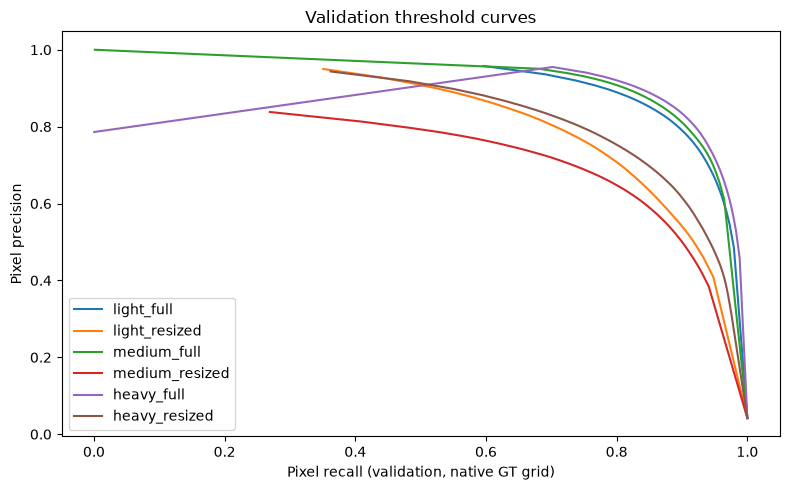

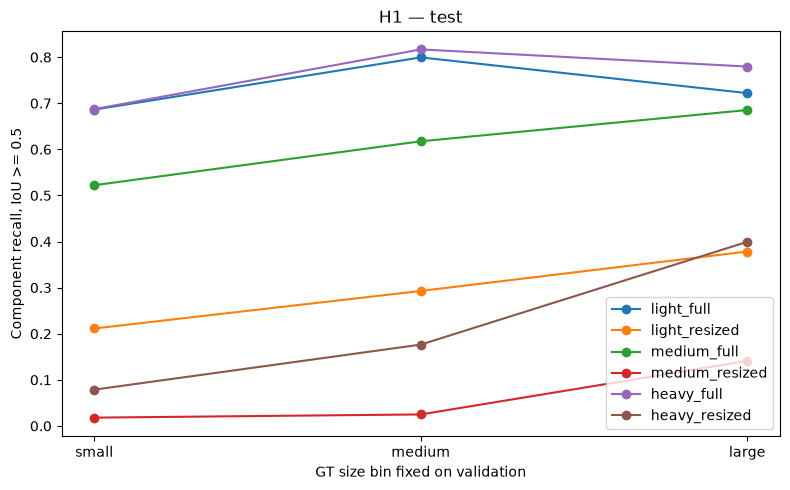

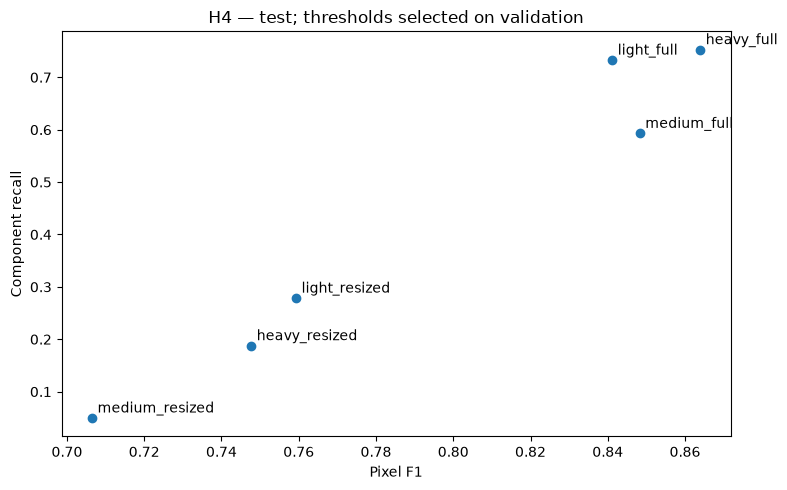

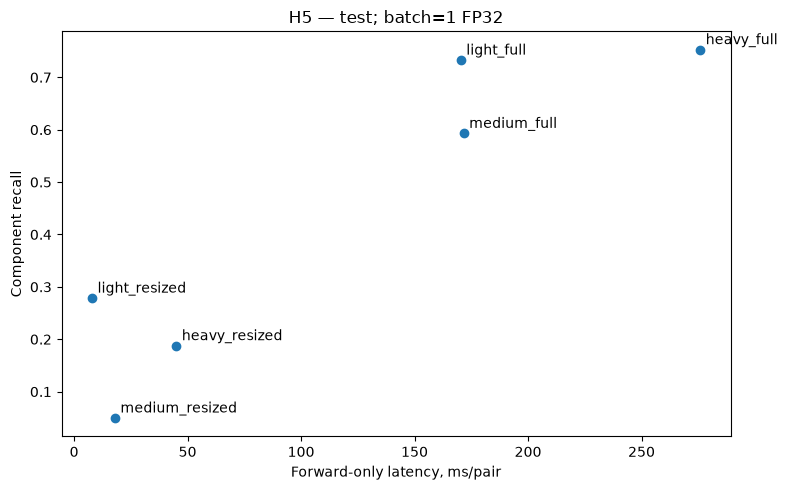

Figures:
artifacts/hypothesis_tests/H1_H5_v1/figures/validation_PR.png
artifacts/hypothesis_tests/H1_H5_v1/figures/H1_test_size_recall.png
artifacts/hypothesis_tests/H1_H5_v1/figures/H4_test_pixel_vs_object.png
artifacts/hypothesis_tests/H1_H5_v1/figures/H5_test_recall_vs_forward_cost.png


In [40]:
figure_files = experiment.plot_reports(REPORT_SPLIT)
print("Figures:", *figure_files, sep="\n")

## 8. Компактный архив результатов

Содержит CSV/JSON, описание протокола, hashes и графики. **Не содержит веса, изображения датасета или полный score cache.**
Если test выключен, архив содержит только validation-анализ; это не итоговая проверка на test.

In [41]:
archive = experiment.export_results()
print("Evaluation split included:", REPORT_SPLIT)
print("Archive:", archive)
display(FileLink(os.path.relpath(archive, Path.cwd())))

Results archive (no weights/images/score cache): artifacts/hypothesis_tests/H1_H5_v1/H1_H5_v1_results.zip
Evaluation split included: test
Archive: artifacts/hypothesis_tests/H1_H5_v1/H1_H5_v1_results.zip


artifacts/hypothesis_tests/H1_H5_v1/H1_H5_v1_results.zip

## Вопросы для интерпретации после эксперимента

**H1:** преимущество Full действительно больше на маленьких областях? Согласуются ли pixel recall, component recall и оценка без граничных областей?

**H2:** Heavy улучшила геометрию, нашла дополнительные GT-области или изменила оба аспекта? Не возникает ли впечатление лучшего обнаружения только из-за строгого IoU matching?

**H3:** сохраняется ли CG при близком validation recall? Не достигает ли одиночная модель того же результата дешевле после изменения порога? Увеличилось ли число FP?

**H4:** меняется ли выбор модели при переходе от pixel F1 к object recall? Насколько устойчивы разности и сохраняется ли вывод при IoU 0.1/0.25/0.5?

**H5:** какие варианты доминируются, а какие представляют разные компромиссы? Какая цена пропуска и проверки нужна, чтобы оправдать более дорогой вариант?

Результаты на LEVIR-CD относятся к этой задаче изменений зданий и не являются проверкой SECOND, качества семантических crops или полного WHERE → WHAT pipeline.

## Источники реализации и проверка пакета

Адаптер основан на файлах предоставленного `levir_hypotheses_context.zip`:
`src/satchange/data/levir_cd.py`, `src/satchange/models/factory.py`, `src/satchange/final_benchmark.py`, `metadata.json` и `validation_results.json` шести вариантов.

Подключённые операции документированы PyTorch/SciPy; конкретные cutoffs, connectivity, IoU и cost-сценарии выше — **явно заданные решения этого эксперимента**, а не восстановленные параметры обучения.

```text
PyTorch torch.load / security:
https://docs.pytorch.org/docs/stable/generated/torch.load.html
PyTorch interpolate:
https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.interpolate.html
SciPy connected-component labelling:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.label.html
SciPy one-to-one assignment:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html
Cheng et al., Boundary IoU (CVPR 2021):
https://arxiv.org/abs/2103.16562
```

Перед выдачей notebook проверены синтетические unit-тесты, полный H1–H5 workflow на искусственном датасете с тестовыми моделями и конструкторы всех шести реальных архитектур из архива. Их числа параметров совпали с сохранёнными benchmark. Конструкторский smoke-test использовал случайные веса и вход 32×32; это **не проверка обученных моделей в Full/Resized режиме**.

В архиве контекста не было весов или изображений LEVIR-CD, поэтому реальные validation/test результаты здесь не вычислялись. Проверка воспроизведения в разделе 4 обязательна.